# Kernel concentration and bandwidth scaling on Google Speech Commands

**How does the spread of a quantum kernel change as the number of qubits grows, and can tuning its bandwidth keep classification accurate at 5,000 shots?**

This notebook repeats the Fashion-MNIST experiment of the project proposal by Muhammad Ahmad Masood and Muhammad Waqas on a speech-only benchmark. It compares two fidelity-kernel support vector machines with a classical RBF support vector machine on the spoken words “yes” and “no” from Google Speech Commands v0.02. Each one-second clip becomes a log-mel spectrogram. Everything after that is unchanged from the Fashion-MNIST notebook: the training-fold standardizer and 16-component PCA, both feature maps, the bandwidth and penalty grids, the shot model, the controls and the hypothesis tests.

| Model | PCA components | Physical qubits | Tuned parameters |
|---|---|---|---|
| IQP fidelity SVM | 2, 4, 6, 8, 10, 12, 14, 16 | 2, 4, 6, 8, 10, 12, 14, 16 | Bandwidth $\lambda$, penalty $C$ |
| Hamiltonian fidelity SVM | Same eight dimensions | 3, 5, 7, 9, 11, 13, 15, 17 | Evolution time $t=\lambda$, penalty $C$ |
| Classical Gaussian RBF SVM | Same eight dimensions | Classical | Kernel parameter $\gamma$, penalty $C$ |

Every output in this notebook was computed by running it from the raw audio. No saved results are loaded.

## 1. Running the notebook

Open the file in JupyterLab or VS Code, select a Python 3.12 kernel and choose **Run All**. On its first run, the notebook streams the official Speech Commands v0.02 archive (2.4 GB) from `download.tensorflow.org`, keeps only the “yes” and “no” recordings in memory and saves the 1,400 selected clips to `speech_commands_yes_no.npz`. Nothing else from the archive is written to disk. Later runs read that file directly. To run offline, put the file in the notebook’s working folder.

If the kernel needs the dependencies, run the following command in its own cell, restart the kernel and run the notebook.

```python
%pip install "numpy>=2" "scipy>=1.14" "pandas>=2.2,<4" "scikit-learn>=1.6" "qiskit>=2.1" "qiskit-aer>=0.17" "qiskit-ibm-runtime>=0.40" matplotlib pylatexenc threadpoolctl ipykernel
```

The complete sweep runs every time. Gram matrices and fold scores are cached in `speech_cache/`, so a rerun reads them back in minutes. Delete that folder to recompute from scratch. The first run takes about an hour on an 8-core laptop and the cache uses a few GB of disk. A Linux C++ compiler with OpenMP accelerates encoding. Result tables are written to `results/` and circuit drawings to `figures/`.

In [1]:
from pathlib import Path
from functools import lru_cache
from io import BytesIO
import base64, ctypes, gzip, hashlib, io, json, os, platform, shutil, struct, subprocess
import tempfile, time, zlib
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import scipy
from scipy.linalg import eigh
from scipy.linalg.blas import zherk
from scipy.spatial.distance import cdist
from scipy.stats import binomtest
import sklearn
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
import qiskit_aer, qiskit_ibm_runtime
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

CACHE = Path("speech_cache")
DIMS = tuple(range(2,17,2))
SCALES = np.logspace(-3,0,4)        # 0.001, 0.01, 0.1, 1
GAMMAS = np.logspace(-4,-1,len(SCALES))
CS = np.array([.006,.015,.03,.0625,.125,.25,.5,1,2,4,8,16,32,64,128,256,512,1024])
SHOTS = (100,1000,5000,10000,100000)
PRIMARY_SHOTS = 5000
T_MAIN, T_ABLATION = 40, (10,25,40)
SEED, HAAR_SEED, BOOTSTRAPS = 42, 1, 1000
WORKERS = min(8, os.cpu_count() or 1)
MODELS = ("IQP","Hamiltonian","RBF")
LABELS = (0,1)
SPEECH_BLOCKS = 20   # Time blocks averaged from the 101 log-mel frames.

def show(frame, digits=4, index=False):
    with pd.option_context("display.max_rows", 130, "display.max_columns", 26,
                           "display.precision", digits, "display.width", 180):
        display(frame if index else frame.reset_index(drop=True))

print(f"Python {platform.python_version()} | Qiskit {qiskit.__version__} | Aer {qiskit_aer.__version__} | "
      f"IBM Runtime {qiskit_ibm_runtime.__version__} | scikit-learn {sklearn.__version__}")

Python 3.12.3 | Qiskit 2.6.2 | Aer 0.17.2 | IBM Runtime 0.49.1 | scikit-learn 1.8.0


## 2. Load the Speech Commands sample

Run the short cell below the two helper definitions to load the data. If `speech_commands_yes_no.npz` is present, NumPy opens it directly. Otherwise the notebook streams the [Speech Commands v0.02 archive](http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz) and creates the sample. The archive’s `testing_list.txt` defines the official test partition and `validation_list.txt` the validation partition. Clips in neither list form the official training partition, as specified by Warden (2018). The split assigns each speaker to one partition only, so no speaker appears in both the training and the test sample. Validation clips are not used.

In [2]:
# Google Speech Commands v0.02 (Warden, 2018). The archive is streamed once and only two words are kept.
SPEECH_URL = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
WORDS = ("yes", "no")
CLASS_NAMES = {0: "yes", 1: "no"}
RATE = 16000

def read_speech_partitions(url=SPEECH_URL):
    import tarfile
    from scipy.io import wavfile
    clips, lists = {}, {}
    with urlopen(Request(url, headers={"User-Agent": "python"}), timeout=120) as response:
        with tarfile.open(fileobj=response, mode="r|gz") as tar:
            for member in tar:
                name = member.name[2:] if member.name.startswith("./") else member.name
                if name in ("testing_list.txt", "validation_list.txt"):
                    lists[name] = set(tar.extractfile(member).read().decode().split())
                elif member.isfile() and name.endswith(".wav") and name.split("/")[0] in WORDS:
                    rate, audio = wavfile.read(io.BytesIO(tar.extractfile(member).read()))
                    if rate != RATE or audio.dtype != np.int16:
                        raise ValueError(f"Unexpected audio format in {name}")
                    clip = np.zeros(RATE, np.int16)   # Clips shorter than one second are zero-padded.
                    clip[:min(RATE, len(audio))] = audio[:RATE]
                    clips[name] = clip
    if set(lists) != {"testing_list.txt", "validation_list.txt"}:
        raise OSError("The archive did not contain the official partition lists.")
    partitions = {}
    for split in ("train", "test"):
        if split == "test":
            names = sorted(n for n in clips if n in lists["testing_list.txt"])
        else:
            names = sorted(n for n in clips if n not in lists["testing_list.txt"]
                           and n not in lists["validation_list.txt"])
        labels = np.array([WORDS.index(n.split("/")[0]) for n in names], dtype=np.uint8)
        partitions[split] = (np.stack([clips[n] for n in names]), labels, np.array(names))
    return partitions

def select_speech_sample(partitions):
    selected = {}
    for split, per_class, seed in (("train", 600, SEED), ("test", 100, SEED + 1)):
        audio, labels, names = partitions[split]
        rng = np.random.default_rng(seed)
        groups = [rng.choice(np.flatnonzero(labels == label), per_class, replace=False) for label in LABELS]
        rows = rng.permutation(np.concatenate(groups))
        selected[f"X_{split}"] = audio[rows]
        selected[f"y_{split}"] = labels[rows]
        selected[f"id_{split}"] = rows
        selected[f"name_{split}"] = names[rows]
    return add_folds(selected)

In [3]:
def fixed_folds(examples, labels):
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    return list(splitter.split(np.zeros(len(labels)), labels))

def add_folds(selected):
    fold = np.empty(len(selected["y_train"]), dtype=np.int8)
    for number, (_, validation) in enumerate(fixed_folds(selected["X_train"], selected["y_train"])):
        fold[validation] = number
    selected["fold"] = fold
    return selected

def write_sample(path, arrays):
    with tempfile.TemporaryDirectory(dir=path.parent.resolve()) as tmp:
        staged = Path(tmp) / path.name
        np.savez_compressed(staged, **arrays)
        staged.replace(path)

@lru_cache(maxsize=1)
def mel_filterbank(bands=40, n_fft=512, rate=RATE):
    mel = lambda f: 2595 * np.log10(1 + f / 700)
    hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = hz(np.linspace(mel(20), mel(rate / 2), bands + 2))
    freqs = np.fft.rfftfreq(n_fft, 1 / rate)
    lower, centre, upper = edges[:-2, None], edges[1:-1, None], edges[2:, None]
    return np.maximum(0, np.minimum((freqs - lower) / (centre - lower), (upper - freqs) / (upper - centre)))

def log_mel(audio, bands=40, n_fft=512, window=400, hop=160):
    """25 ms Hann windows every 10 ms, 40 triangular mel bands, natural log of the band power."""
    x = np.pad(np.asarray(audio, dtype=np.float64) / 32768, ((0, 0), (n_fft // 2, n_fft // 2)))
    frames = np.lib.stride_tricks.sliding_window_view(x, window, axis=1)[:, ::hop]
    power = np.abs(np.fft.rfft(frames * np.hanning(window), n=n_fft)) ** 2
    return np.log(power @ mel_filterbank(bands, n_fft).T + 1e-6)

def speech_features(audio, blocks=SPEECH_BLOCKS):
    # Average the 101 frames in equal time blocks, then flatten to blocks x 40 columns.
    spectrogram = log_mel(audio)
    pooled = [part.mean(axis=1) for part in np.array_split(spectrogram, blocks, axis=1)]
    return np.ascontiguousarray(np.stack(pooled, axis=1).reshape(len(audio), -1))

In [4]:
sample_file = Path("speech_commands_yes_no.npz")
if not sample_file.is_file():
    write_sample(sample_file, select_speech_sample(read_speech_partitions()))
with np.load(sample_file, allow_pickle=False) as data:
    SAMPLE = dict(data)

### Sample, labels, features and fixed folds

Label **0** is the word “yes” and label **1** is “no”. The reproducible sample is balanced by class within each official partition. The 1,200 training clips contain 600 of each word. The 200 held-out clips contain 100 of each. The sampler draws without replacement with NumPy seed 42 for training and 43 for testing from the sorted file list of each partition. Row numbers are zero-based within that list, and the file names are stored with the sample.

Every clip is zero-padded or cut to 16,000 samples. A 512-point FFT of 25 ms Hann windows every 10 ms gives 101 frames. These are mapped to 40 triangular mel bands between 20 Hz and 8 kHz and logged. The frames are averaged in 20 equal time blocks, giving 800 columns per clip. This fixed transform uses no labels and no other clips. It plays the role of Fashion-MNIST’s 784 pixels.

Each of the five shuffled stratified folds contains 960 fitting clips and 240 validation clips. A columnwise standardizer and 16-component, unwhitened PCA are fitted on that fold’s 960 fitting clips. Taking the leading $n$ columns gives the nested dimension sweep. The final standardizer and PCA are fitted on all 1,200 training clips, then applied to the 200 official test clips.

In [5]:
X, y = SAMPLE["X_train"], SAMPLE["y_train"]
X_test, y_test = SAMPLE["X_test"], SAMPLE["y_test"]
train_ids, test_ids = SAMPLE["id_train"], SAMPLE["id_test"]
assert X.shape==(1200,RATE) and X_test.shape==(200,RATE) and X.dtype==np.int16
assert len(np.unique(train_ids))==1200 and len(np.unique(test_ids))==200
assert np.unique(y,return_counts=True)[1].tolist()==[600,600]
assert np.unique(y_test,return_counts=True)[1].tolist()==[100,100]
np.testing.assert_array_equal(np.unique(y),LABELS)
np.testing.assert_array_equal(np.unique(y_test),LABELS)
FOLDS=fixed_folds(X,y)
assert np.array_equal(np.sort(np.concatenate([v for _,v in FOLDS])),np.arange(1200))
fold_assignment=np.empty(1200,dtype=np.int8)
for number,(training,validation) in enumerate(FOLDS):
    assert len(training)==960 and len(validation)==240 and not np.intersect1d(training,validation).size
    fold_assignment[validation]=number
np.testing.assert_array_equal(fold_assignment,SAMPLE["fold"])
F,F_test=speech_features(X),speech_features(X_test)
def project(training,other):
    scaler=StandardScaler().fit(training)
    standardized=scaler.transform(training)
    pca=PCA(n_components=max(DIMS),svd_solver="full")
    with threadpool_limits(limits=min(4,WORKERS),user_api="blas"):
        fit_x=pca.fit_transform(standardized)
        other_x=pca.transform(scaler.transform(other))
    return np.ascontiguousarray(np.vstack([fit_x,other_x]))
# Folds each own a scaler and PCA. Final projection uses the 1,200 training rows only.
fold_views=[project(F[tr],F[va]) for tr,va in FOLDS]
final_view=project(F,F_test)
data_fingerprint=hashlib.sha256(X.tobytes()+y.tobytes()+X_test.tobytes()+y_test.tobytes()+
                                train_ids.astype("<i8").tobytes()+test_ids.astype("<i8").tobytes()+
                                fold_assignment.tobytes()).hexdigest()
show(pd.DataFrame({"Partition":["Training","Held-out test"],f"{CLASS_NAMES[0]} (0)":[600,100],
                   f"{CLASS_NAMES[1]} (1)":[600,100],"First five official row IDs":[train_ids[:5],test_ids[:5]]}))
print(f"Feature matrix before PCA: {F.shape[1]:,} columns.")
print("Fixed split / folds SHA-256",data_fingerprint)

,Partition,yes (0),no (1),First five official row IDs
0,Training,600,600,"[1694, 5133, 3018, 2896, 3651]"
1,Held-out test,100,100,"[419, 769, 380, 743, 238]"


Feature matrix before PCA: 800 columns.
Fixed split / folds SHA-256 07cd66860ec97fcfde5c30786ce320357d0d1af69bda0243b6d2d1581c1306cb


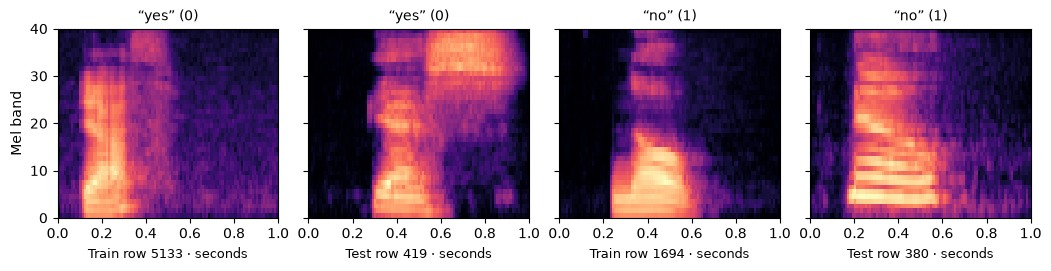

In [6]:
fig,axes=plt.subplots(1,4,figsize=(10.4,2.6),layout="constrained",sharey=True)
for ax,(name,clips,labels,ids,label) in zip(axes,[
    ("Train",X,y,train_ids,0),("Test",X_test,y_test,test_ids,0),
    ("Train",X,y,train_ids,1),("Test",X_test,y_test,test_ids,1)]):
    idx=np.flatnonzero(labels==label)[0]
    ax.imshow(log_mel(clips[idx:idx+1])[0].T,origin="lower",aspect="auto",cmap="magma",
              extent=(0,1,0,40),interpolation="nearest")
    ax.set_title(f"“{CLASS_NAMES[label]}” ({label})",fontsize=10)
    ax.set_xlabel(f"{name} row {ids[idx]} · seconds",fontsize=9)
axes[0].set_ylabel("Mel band")
plt.show()

## 3. Quantum feature maps and classical kernel

The quantum classifiers use $K(x,z)=|\langle\psi(z)\mid\psi(x)\rangle|^2$, the all-zero probability after preparing $U(x)$ and applying $U(z)^\dagger$.

**IQP.** Write $u=\lambda x$. Two rounds of Hadamards and diagonal interactions prepare $U_Z(u)H^{\otimes n}U_Z(u)H^{\otimes n}|0^n\rangle$, where
$$U_Z(u)=\exp\!\left(i\sum_j u_j Z_j+i\sum_{j<k}u_j u_k Z_j Z_k\right).$$
Qiskit implements these positive exponents with `rz(-2*u[j])` and `rzz(-2*u[j]*u[k])`. Every distinct pair of qubits interacts.

**Hamiltonian evolution.** Each of the $n$ features weights one nearest-neighbor bond on $n+1$ qubits. We initialize a product of independent Haar-random single-qubit states with a fixed seed. Each of $T=40$ first-order Trotter steps visits the bonds from left to right. On bond $j$ the unitary is $\exp[-i\lambda x_j (X_jX_{j+1}+Y_jY_{j+1}+Z_jZ_{j+1})/T]$. The three terms on one bond commute. The ablation repeats the construction at $T=10$ and $25$.

**Classical baseline.** The RBF kernel is $K(x,z)=\exp[-\gamma\|x-z\|^2]$. The baseline uses the same projected examples and fixed folds as the quantum models.

In [7]:
def haar_angles(q,seed=HAAR_SEED):
    u=np.random.default_rng(seed).uniform(size=(q,2))
    return 2*np.arcsin(np.sqrt(u[:,0])),2*np.pi*u[:,1]

def initial_state(q,seed=HAAR_SEED):
    theta,phi=haar_angles(q,seed)
    state=np.ones(1,np.complex128)
    for a,b in zip(theta,phi):
        state=np.kron([np.cos(a/2),np.exp(1j*b)*np.sin(a/2)],state)
    return state

def feature_circuit(model,x,scale,steps=T_MAIN,seed=HAAR_SEED,decimals=None):
    x=np.asarray(x)  # Numeric inputs or a Qiskit ParameterVector.
    n=len(x)
    def angle(a):
        return a if decimals is None else np.round(a,decimals)
    if model=="IQP":
        qc=QuantumCircuit(n,name="IQP")
        for _ in range(2):
            qc.h(range(n))
            for j in range(n):
                qc.rz(angle(-2*scale*x[j]),j)
                for k in range(j+1,n):
                    qc.rzz(angle(-2*scale**2*x[j]*x[k]),j,k)
        return qc
    if model!="Hamiltonian" or steps<1:
        raise ValueError((model,steps))
    qc=QuantumCircuit(n+1,name="Heisenberg")
    theta,phi=haar_angles(n+1,seed)
    for j in range(n+1):
        qc.ry(theta[j],j)
        qc.rz(phi[j],j)
    for _ in range(steps):
        for j,a in enumerate(angle(2*scale*x/steps)):
            qc.rxx(a,j,j+1)
            qc.ryy(a,j,j+1)
            qc.rzz(a,j,j+1)
    return qc

def overlap_circuit(model,x,z,scale,steps=T_MAIN,decimals=None):
    left=feature_circuit(model,x,scale,steps,decimals=decimals)
    right=feature_circuit(model,z,scale,steps,decimals=decimals)
    qc=left.compose(right.inverse())
    qc.measure_all()
    return qc

@lru_cache(maxsize=2)
def pauli_signs(n):
    signs=(1-2*((np.arange(2**n)[None,:]>>np.arange(n)[:,None])&1)).astype(float)
    lo,hi=np.triu_indices(n,1)
    return signs,lo,hi,signs[lo]*signs[hi]

def numpy_states(points,model,scale,steps=T_MAIN,seed=HAAR_SEED,decimals=None):
    points=np.atleast_2d(np.asarray(points,dtype=float))
    m,n=points.shape
    if model=="IQP":
        u=scale*points
        if decimals is None:
            s=np.zeros((m,1))
            for a in u.T:
                s=np.concatenate([s+a[:,None],s-a[:,None]],axis=1)
            phase=np.exp(1j*(s+0.5*s*s))
        else:
            signs,lo,hi,pair_signs=pauli_signs(n)
            angles=np.round(-2*u,decimals)
            pairs=np.round(-2*u[:,lo]*u[:,hi],decimals)
            with threadpool_limits(limits=min(WORKERS,4),user_api="blas"):
                phi=-0.5*(angles@signs+pairs@pair_signs)
            phase=np.exp(1j*phi)
        psi=phase.copy()
        for j in range(n):
            part=psi.reshape(m,-1,2,2**j)
            a,b=part[:,:,0].copy(),part[:,:,1].copy()
            part[:,:,0],part[:,:,1]=a+b,a-b
        return psi*phase/(2**n)
    if model!="Hamiltonian" or steps<1:
        raise ValueError((model,steps))
    theta=2*scale*points/steps
    if decimals is not None:
        theta=np.round(theta,decimals)
    rel=0.5*np.expm1(2j*theta)
    psi=np.tile(initial_state(n+1,seed),(m,1))
    for _ in range(steps):
        for j in range(n):
            p=psi.reshape(m,-1,4,2**j)
            delta=(p[:,:,1]-p[:,:,2])*rel[:,j,None,None]
            p[:,:,1]+=delta
            p[:,:,2]-=delta
    return psi

### Exact statevectors at 16 and 17 qubits

The exact evaluator prepares a complex double-precision state for each clip, then squares the magnitudes of the state inner products. The IQP implementation uses a Walsh–Hadamard transform. The Heisenberg implementation uses $XX+YY+ZZ=2\,\mathrm{SWAP}-I$ on each bond. Both omit only global phases. The square training matrix is $1{,}200\times1{,}200$ and the test-by-training matrix is $200\times1{,}200$.

In [8]:
CPP_SOURCE = r'''
#include <algorithm>
#include <cmath>
#include <cstdint>
#include <vector>
#ifdef _OPENMP
#include <omp.h>
#endif

// Interleaved real and imaginary double amplitudes, in Qiskit little-endian order.
extern "C" void encode(const double* features, int rows, int n, int ham,
                       double scale, int steps, int decimals, const double* initial,
                       int workers, double* states) {
    const int width = 1 << (n + ham);
    #pragma omp parallel for num_threads(workers) schedule(static)
    for (int row = 0; row < rows; ++row) {
        const double* x = features + row * n;
        double* state = states + static_cast<int64_t>(row) * 2 * width;
        if (ham) {
            std::copy_n(initial, 2 * width, state);
            std::vector<double> cr(n), ci(n);
            for (int j = 0; j < n; ++j) {
                double angle = 2.0 * scale * x[j] / steps;
                if (decimals >= 0) {
                    const double factor = std::pow(10.0, decimals);
                    angle = std::nearbyint(angle * factor) / factor;
                }
                // Antisymmetric SWAP eigenstate gets relative phase exp(2i*angle).
                cr[j] = -std::sin(angle) * std::sin(angle);
                ci[j] = 0.5 * std::sin(2.0 * angle);
            }
            for (int t = 0; t < steps; ++t) {
                for (int j = 0; j < n; ++j) {
                    const int stride = 1 << j;
                    const double real = cr[j], imag = ci[j];
                    for (int group = 0; group < width; group += 4 * stride) {
                        double* a = state + 2 * (group + stride);
                        double* b = state + 2 * (group + 2 * stride);
                        #pragma omp simd
                        for (int k = 0; k < stride; ++k) {
                            const double dr = a[2*k] - b[2*k];
                            const double di = a[2*k+1] - b[2*k+1];
                            const double re = real * dr - imag * di;
                            const double im = real * di + imag * dr;
                            a[2*k] += re; a[2*k+1] += im;
                            b[2*k] -= re; b[2*k+1] -= im;
                        }
                    }
                }
            }
        } else {
            std::vector<double> sums(width), phase(2 * width);
            for (int j = 0; j < n; ++j) {
                const double v = scale * x[j];
                const int stride = 1 << j;
                #pragma omp simd
                for (int k = 0; k < stride; ++k) {
                    sums[k+stride] = sums[k] - v;
                    sums[k] += v;
                }
            }
            for (int k = 0; k < width; ++k) {
                const double a = sums[k] + 0.5 * sums[k] * sums[k];
                phase[2*k] = state[2*k] = std::cos(a);
                phase[2*k+1] = state[2*k+1] = std::sin(a);
            }
            for (int stride = 1; stride < width; stride *= 2)
                for (int group = 0; group < width; group += 2 * stride) {
                    double* a = state + 2 * group;
                    double* b = state + 2 * (group + stride);
                    #pragma omp simd
                    for (int k = 0; k < 2 * stride; ++k) {
                        const double l = a[k], r = b[k];
                        a[k] = l + r; b[k] = l - r;
                    }
                }
            #pragma omp simd
            for (int k = 0; k < width; ++k) {
                const double re = state[2*k], im = state[2*k+1];
                state[2*k] = (re * phase[2*k] - im * phase[2*k+1]) / width;
                state[2*k+1] = (re * phase[2*k+1] + im * phase[2*k]) / width;
            }
        }
    }
}
'''

In [9]:
USE_NATIVE = True
STATE_RAM_MIB = 2048   # Larger state batches are memory-mapped to the cache folder.
@lru_cache(maxsize=1)
def accelerator():
    if not USE_NATIVE or platform.system()!="Linux" or not shutil.which("g++"):
        return None
    directory=CACHE/"native"
    directory.mkdir(parents=True,exist_ok=True)
    tag=hashlib.sha256(CPP_SOURCE.encode()).hexdigest()[:12]
    target=directory/f"states_{tag}.so"
    if not target.exists():
        with tempfile.TemporaryDirectory(dir=directory) as tmp:
            src=Path(tmp)/"states.cpp"
            lib=Path(tmp)/"states.so"
            src.write_text(CPP_SOURCE)
            cmd=["g++","-O3","-fopenmp","-fPIC","-shared",str(src),"-o",str(lib)]
            try:
                subprocess.run(cmd,check=True,capture_output=True)
            except (OSError,subprocess.CalledProcessError):
                return None
            lib.replace(target)
    lib=ctypes.CDLL(str(target.resolve()))
    ptr,num=ctypes.c_void_p,ctypes.c_int
    fun=lib.encode
    fun.argtypes=[ptr,num,num,num,ctypes.c_double,num,num,ptr,num,ptr]
    fun.restype=None
    return fun

def prepare_states(points,model,scale,steps,seed,decimals,out):
    x=np.ascontiguousarray(points,dtype=np.float64)
    n=x.shape[1]
    use=accelerator()
    if use is None or (model=="IQP" and decimals is not None):
        batch=max(1,min(len(x),int(70*2**20/(out.shape[1]*64))))
        for i in range(0,len(x),batch):
            out[i:i+batch]=numpy_states(x[i:i+batch],model,scale,steps,seed,decimals)
    else:
        init=initial_state(n+1,seed) if model=="Hamiltonian" else np.ones(1,complex)
        use(x.ctypes.data,len(x),n,int(model=="Hamiltonian"),float(scale),int(steps),
            -1 if decimals is None else int(decimals),init.ctypes.data,WORKERS,out.ctypes.data)

def fidelity_matrix(points,model,scale,steps=T_MAIN,seed=HAAR_SEED,decimals=None):
    if model not in ("IQP","Hamiltonian"):
        raise ValueError(model)
    m,n=points.shape
    width=2**(n+int(model=="Hamiltonian"))
    CACHE.mkdir(parents=True,exist_ok=True)
    with tempfile.TemporaryDirectory(dir=CACHE) as tmp:
        shape=(m,width)
        if m*width*16 > STATE_RAM_MIB*2**20:
            states=np.memmap(Path(tmp)/"states.bin",shape=shape,dtype=np.complex128,mode="w+")
        else:
            states=np.empty(shape,dtype=np.complex128)
        prepare_states(points,model,scale,steps,seed,decimals,states)
        with threadpool_limits(limits=WORKERS,user_api="blas"):
            # Hermitian rank-k GEMM computes one triangle, with no redundant complex conjugate array.
            overlaps=zherk(1.,states.T,trans=2,lower=1)
        del states
        np.testing.assert_allclose(np.real(overlaps.diagonal()),1.,atol=2e-10,rtol=0)
        lower=np.tril(abs(overlaps)**2,-1)
        return np.clip(lower+lower.T+np.eye(m),0.,1.)

def packed_path(model,n,scale,fold,steps,seed,decimals):
    signature=hashlib.sha256(json.dumps([data_fingerprint,"standard-scaler/full-pca16/v1",
          model,int(n),float(scale),int(fold),int(steps),int(seed),decimals]).encode()).hexdigest()
    return CACHE/"gram"/f"{signature}.npy"

def kernel(model,n,scale,fold=-1,steps=T_MAIN,seed=HAAR_SEED,decimals=None):
    points=final_view if fold==-1 else fold_views[fold]
    path=packed_path(model,n,scale,fold,steps,seed,decimals)
    i,j=np.tril_indices(len(points),-1)
    if path.is_file():
        packed=np.load(path,allow_pickle=False)
        if packed.shape!=(len(i),):
            raise ValueError(f"Damaged kernel file {path}")
        K=np.eye(len(points))
        K[i,j]=K[j,i]=packed
        return K
    K=fidelity_matrix(points[:,:n],model,scale,steps,seed,decimals)
    path.parent.mkdir(parents=True,exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent,suffix=".npy",delete=False) as file:
        tmp=Path(file.name)
        np.save(file,K[i,j],allow_pickle=False)
    tmp.replace(path)
    return K

### Circuit verification

The following cell compares explicit Qiskit circuits, the vectorized NumPy model and the accelerated fidelity calculation for both maps. It checks full and rounded gate angles. The same test compares independently constructed overlap circuits with their all-zero probabilities.

In [10]:
check_rows=[]
for n in (2,4):
    p=final_view[[0,7,1200],:n]
    for model in ("IQP","Hamiltonian"):
        for decimals in (None,2):
            factor=.13
            T=3
            expected=np.stack([Statevector.from_instruction(feature_circuit(model,z,factor,T,decimals=decimals)).data for z in p])
            native=np.empty_like(expected)
            prepare_states(p,model,factor,T,HAAR_SEED,decimals,native)
            portable=numpy_states(p,model,factor,T,decimals=decimals)
            direct=abs(expected@expected.conj().T)**2
            fast=fidelity_matrix(p,model,factor,T,decimals=decimals)
            err=float(abs(fast-direct).max())
            independent=float(np.max(abs(1-abs(np.sum(expected.conj()*portable,axis=1))**2)))
            native_error=float(np.max(abs(1-abs(np.sum(expected.conj()*native,axis=1))**2)))
            stripped=overlap_circuit(model,p[0],p[2],factor,T,decimals).remove_final_measurements(inplace=False)
            p0=float(abs(Statevector.from_instruction(stripped).data[0])**2)
            assert max(err,independent,native_error,abs(p0-fast[0,2]))<2e-10
            check_rows.append([model,n,n+int(model=="Hamiltonian"),str(decimals),err,independent,native_error,abs(p0-fast[0,2])])
show(pd.DataFrame(check_rows,columns=["Map","PCs","Physical qubits","Angle decimals","Max kernel error",
                                      "NumPy state infidelity","Accelerator state infidelity","All-zero probability error"]),12)

,Map,PCs,Physical qubits,Angle decimals,Max kernel error,NumPy state infidelity,Accelerator state infidelity,All-zero probability error
0,IQP,2,2,None,2.442490654175e-15,1.110223024625e-15,1.110223024625e-15,1.332267629550e-15
1,IQP,2,2,2,1.332267629550e-15,6.661338147751e-16,6.661338147751e-16,3.330669073875e-16
2,Hamiltonian,2,3,None,2.664535259100e-15,1.332267629550e-15,1.332267629550e-15,2.775557561563e-16
3,Hamiltonian,2,3,2,8.881784197001e-16,4.440892098501e-16,4.440892098501e-16,2.775557561563e-16
4,IQP,4,4,None,4.440892098501e-15,2.442490654175e-15,2.220446049250e-15,4.926614671774e-16
5,IQP,4,4,2,3.552713678801e-15,1.776356839400e-15,1.776356839400e-15,6.245004513517e-17
6,Hamiltonian,4,5,None,2.886579864025e-15,2.664535259100e-15,2.664535259100e-15,1.665334536938e-16
7,Hamiltonian,4,5,2,3.108624468950e-15,1.554312234475e-15,1.554312234475e-15,0.000000000000e+00


### Drawing the quantum circuits

The drawings below are generated from the same `feature_circuit` and `overlap_circuit` functions that the experiment uses, with a symbolic bandwidth $\lambda$ and symbolic features $x_j$, $z_j$. They are shown at four components so every gate is legible. The IQP map has the same structure at every width: two layers of Hadamards, single-qubit $R_Z(-2\lambda x_j)$ and an $R_{ZZ}(-2\lambda^2 x_j x_k)$ on every pair of qubits. The Hamiltonian map prepares a fixed Haar-random product state with $R_Y$ and $R_Z$, then applies $T$ Trotter steps of $R_{XX}R_{YY}R_{ZZ}(2\lambda x_j/T)$ along the chain. Only the first two of its $T=40$ steps are drawn. The kernel circuit applies $U(x)$, then $U(z)^\dagger$, and measures every qubit. $K(x,z)$ is the frequency of the all-zero outcome. The table gives the full-size resource counts for the first training example at every width. Each PNG is also saved in `figures/`.

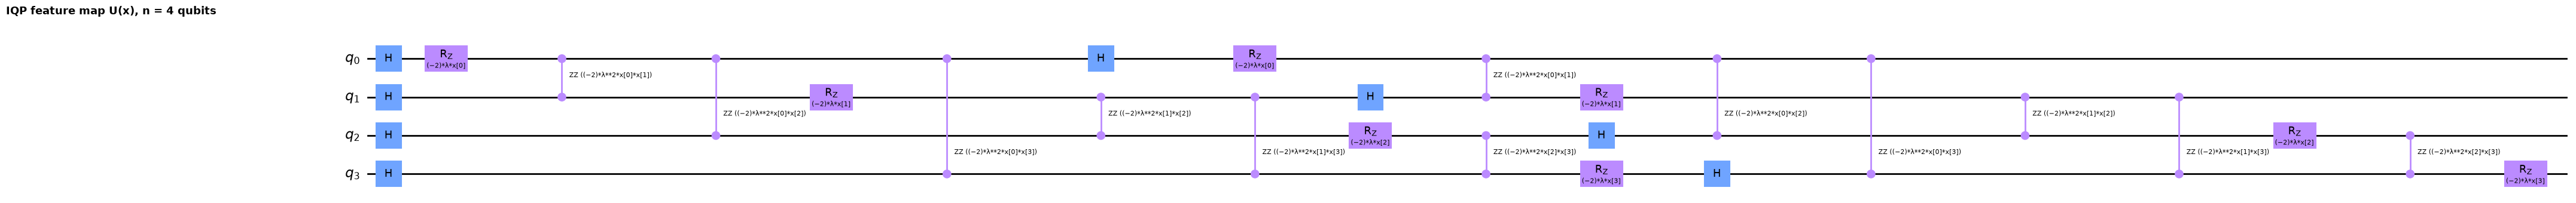

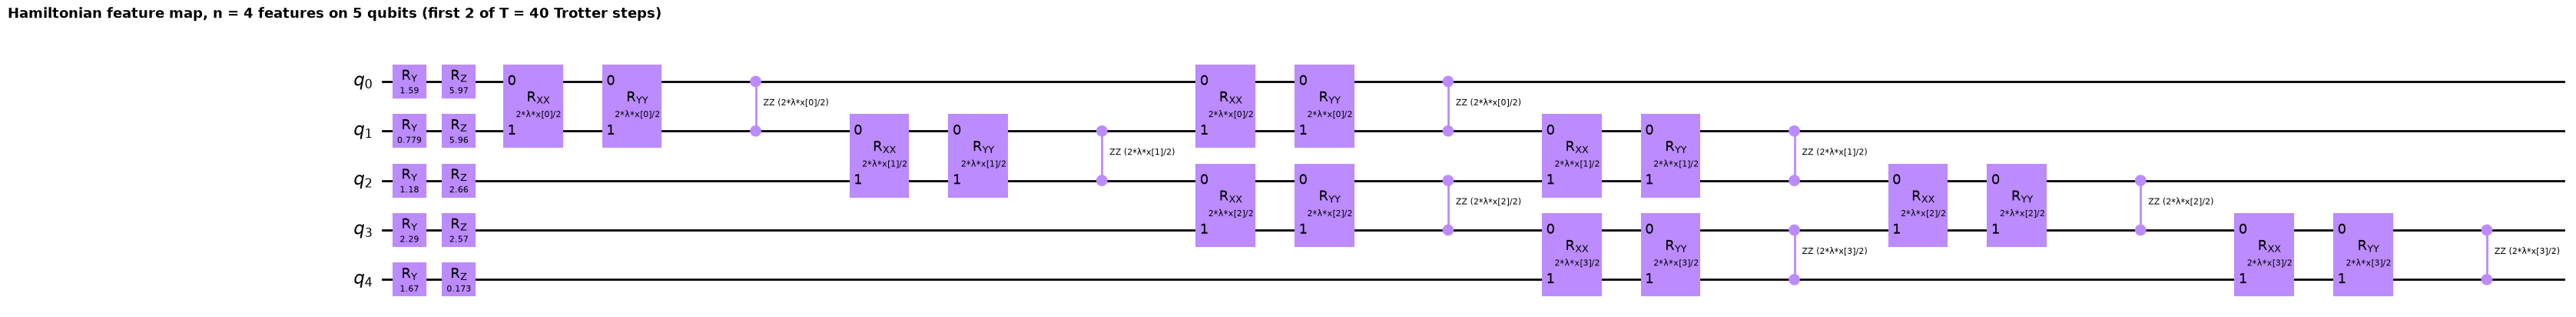

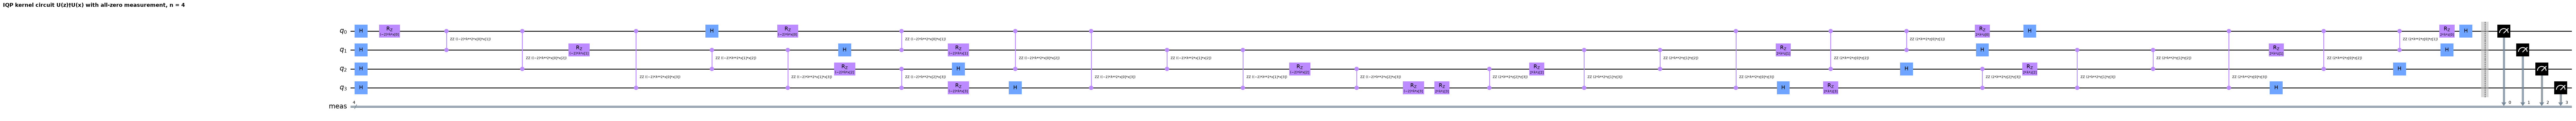

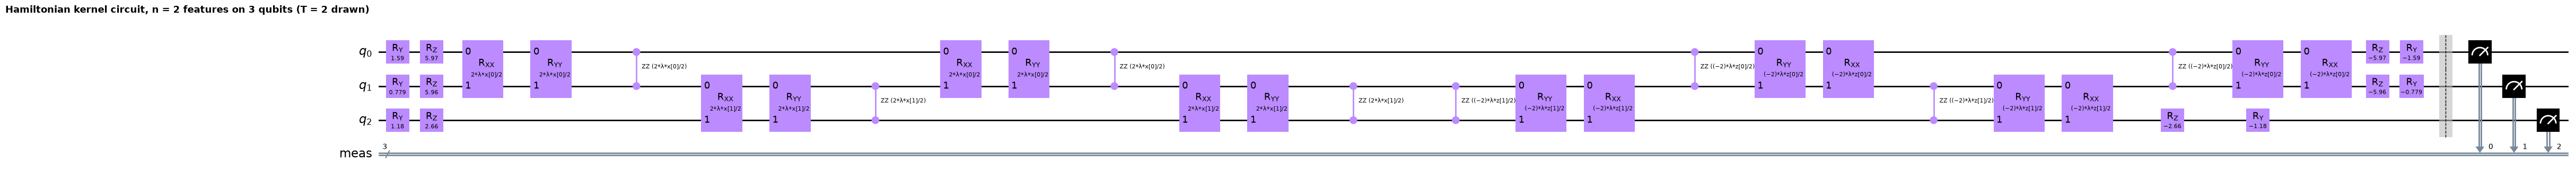

One feature map per row. A kernel-entry circuit applies U(x) and U(z)† and so doubles these counts.


,Map,PCs,Physical qubits,Feature-map depth,Two-qubit rotations,CX after compilation (all-to-all),Compiled depth
0,IQP,2,2,7,2,4,13
1,IQP,4,4,13,12,24,34
2,IQP,6,6,19,30,60,52
3,IQP,8,8,25,56,112,70
4,IQP,10,10,31,90,180,88
5,IQP,12,12,37,132,264,106
6,IQP,14,14,43,182,364,124
7,IQP,16,16,49,240,480,142
8,Hamiltonian,2,3,242,240,480,1202
9,Hamiltonian,4,5,248,480,960,1232


In [11]:
from qiskit.circuit import Parameter, ParameterVector
FIGURES=Path("figures")
FIGURES.mkdir(exist_ok=True)
lam=Parameter("λ")
xs,zs=ParameterVector("x",4),ParameterVector("z",4)
drawings=[
    ("iqp_feature_map","IQP feature map U(x), n = 4 qubits",feature_circuit("IQP",xs,lam)),
    ("hamiltonian_feature_map","Hamiltonian feature map, n = 4 features on 5 qubits (first 2 of T = 40 Trotter steps)",
     feature_circuit("Hamiltonian",xs,lam,steps=2)),
    ("iqp_kernel_circuit","IQP kernel circuit U(z)†U(x) with all-zero measurement, n = 4",overlap_circuit("IQP",xs,zs,lam)),
    ("hamiltonian_kernel_circuit","Hamiltonian kernel circuit, n = 2 features on 3 qubits (T = 2 drawn)",
     overlap_circuit("Hamiltonian",xs[:2],zs[:2],lam,steps=2)),
]
for name,title,qc in drawings:
    fig=qc.draw("mpl",fold=-1,style="clifford")
    fig.suptitle(title,x=0.02,ha="left",fontsize=13,fontweight="bold")
    fig.savefig(FIGURES/f"{name}.png",dpi=150,bbox_inches="tight")
    display(fig)
    plt.close(fig)

resources=[]
for model in ("IQP","Hamiltonian"):
    for n in DIMS:
        qc=feature_circuit(model,final_view[0,:n],1.)
        ops=qc.count_ops()
        compiled=transpile(qc,basis_gates=["rz","sx","x","cx"],optimization_level=1,seed_transpiler=SEED)
        resources.append({"Map":model,"PCs":n,"Physical qubits":qc.num_qubits,"Feature-map depth":qc.depth(),
                          "Two-qubit rotations":sum(ops.get(g,0) for g in ("rzz","rxx","ryy")),
                          "CX after compilation (all-to-all)":compiled.count_ops().get("cx",0),
                          "Compiled depth":compiled.depth()})
print("One feature map per row. A kernel-entry circuit applies U(x) and U(z)† and so doubles these counts.")
show(pd.DataFrame(resources))

## 4. Model selection, shots and evaluation

For each model and dimension, the five folds select the scale and $C$ jointly by mean validation accuracy. The quantum grid is $\lambda\in\{10^{-3},10^{-2},10^{-1},10^0\}$. The RBF uses the same number of logarithmic candidates, $\gamma\in\{10^{-4},10^{-3},10^{-2},10^{-1}\}$. The proposal specifies the quantum endpoints and equal grid sizes. These are our choices of resolution and RBF range. The 18 penalties run from 0.006 to 1,024. Exact ties go to the smaller scale, then the smaller $C$.

The exact and 5,000-shot quantum runs each have their own validation-selected parameters. The 100-, 1,000-, 10,000- and 100,000-shot runs keep the 5,000-shot winners to isolate the effect of shots. An ideal overlap with true probability $p$ yields $k\sim\mathrm{Binomial}(S,p)$ all-zero outcomes in $S$ shots. We draw one $k/S$ per unique training pair, mirror it and draw independent test–training entries. Ideal self-overlaps equal one. Each noisy training matrix is projected onto the nearest PSD matrix in Frobenius norm by clipping negative eigenvalues. Test–training entries keep their measured values.

Each fit records train and held-out accuracy, balanced accuracy, class recalls, confusion counts, class-specific support-vector counts and $\|K-I\|_F$. The ground-truth labels are the first argument in all classification metrics. A held-out score always uses the same 200 test clips.

In [12]:
def rng_for(*items):
    key=json.dumps(items,sort_keys=True,default=lambda v:v.item()).encode()
    return np.random.default_rng(int.from_bytes(hashlib.sha256(key).digest()[:8],"little"))

def psd_projection(K):
    with threadpool_limits(limits=min(2,WORKERS),user_api="blas"):
        eigen,U=eigh((K+K.T)*.5,driver="evd",check_finite=False)
        positive=np.maximum(eigen,0)
        A=(U*positive)@U.T
    return (A+A.T)*.5,float(np.linalg.norm(np.minimum(eigen,0))/np.linalg.norm(eigen))

def measured_blocks(K,L,shots,key):
    r=rng_for("ideal-binomial-v1",SEED,*key,int(shots))
    i,j=np.tril_indices(len(K),-1)
    sampled=np.eye(len(K))
    obs=r.binomial(shots,np.clip(K[i,j],0,1))/shots
    sampled[i,j]=sampled[j,i]=obs
    cross=r.binomial(shots,np.clip(L,0,1))/shots
    psd,shift=psd_projection(sampled)
    return psd,cross,obs,shift

def blocks(model,n,scale,fold=-1,steps=T_MAIN,decimals=None):
    v=final_view if fold==-1 else fold_views[fold]
    m=len(y) if fold==-1 else len(FOLDS[fold][0])
    if model=="RBF":
        a,b=v[:m,:n],v[m:,:n]
        return np.exp(-scale*cdist(a,a,"sqeuclidean")),np.exp(-scale*cdist(b,a,"sqeuclidean"))
    g=kernel(model,n,scale,fold,steps,decimals=decimals)
    return np.ascontiguousarray(g[:m,:m]),np.ascontiguousarray(g[m:,:m])

def fold_result(model,n,scale,fold,steps=T_MAIN):
    tr,va=FOLDS[fold]
    K,L=blocks(model,n,scale,fold,steps)
    settings=[("exact",K,L)]
    if model!="RBF":
        a,b,_,_=measured_blocks(K,L,PRIMARY_SHOTS,[model,n,scale,steps,fold])
        settings.append(("5000",a,b))
    records=[]
    for condition,a,b in settings:
        for c in CS:
            svc=SVC(C=float(c),kernel="precomputed").fit(a,y[tr])
            count=int(np.sum(svc.predict(b)==y[va]))
            records.append(dict(model=model,n=n,scale=float(scale),T=0 if model!="Hamiltonian" else steps,
                                fold=fold,C=float(c),condition=condition,correct=count,total=len(va)))
    return records

def protocol_id():
    p=[data_fingerprint,DIMS,SCALES.tolist(),GAMMAS.tolist(),CS.tolist(),SHOTS,PRIMARY_SHOTS,
       T_MAIN,T_ABLATION,SEED,HAAR_SEED,BOOTSTRAPS,"proposal-v1"]
    return hashlib.sha256(json.dumps(p).encode()).hexdigest()
def grid_record_path(model,n,scale,fold,steps):
    return CACHE/"cv"/protocol_id()/f"{model}_{n}_{float(scale).hex()}_{fold}_{steps}.json"
def cache_json(path, obj):
    path.parent.mkdir(parents=True,exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w",encoding="utf-8",dir=path.parent,delete=False) as f:
        tmp=Path(f.name)
        json.dump(obj,f,allow_nan=False)
    tmp.replace(path)
def cached_fold(model,n,scale,fold,steps=T_MAIN):
    path=grid_record_path(model,n,scale,fold,steps)
    if path.is_file():
        return json.loads(path.read_text())
    out=fold_result(model,n,scale,fold,steps)
    cache_json(path,out)
    return out

def project_cv():
    records=[]
    for n in DIMS:
        for model in MODELS:
            for scale in (GAMMAS if model=="RBF" else SCALES):
                for fold in range(len(FOLDS)):
                    records.extend(cached_fold(model,n,float(scale),fold))
    return pd.DataFrame(records)

def summarize_cv(folds):
    keys=["model","n","T","condition","scale","C"]
    g=folds.groupby(keys,as_index=False).agg(correct=("correct","sum"),total=("total","sum"),folds=("fold","nunique"))
    assert (g.folds==5).all() and (g.total==len(y)).all()
    g["cv_accuracy"]=g.correct/g.total
    return g

def winners(scores):
    keys=["model","n","T","condition"]
    return (scores.sort_values(["correct","scale","C"],ascending=[False,True,True])
            .drop_duplicates(keys).sort_values(keys).reset_index(drop=True))

def model_scores(K,L,c):
    svc=SVC(C=float(c),kernel="precomputed").fit(K,y)
    pt,pe=svc.predict(K),svc.predict(L)
    tn,fp,fn,tp=confusion_matrix(y_test,pe,labels=list(LABELS)).ravel()
    test=float(accuracy_score(y_test,pe))
    bal=float(balanced_accuracy_score(y_test,pe))
    assert tn+fp+fn+tp==200 and np.isclose(bal,(tn/(tn+fp)+tp/(tp+fn))/2)
    sv0,sv2=map(int,svc.n_support_)
    row=dict(train_accuracy=accuracy_score(y,pt),test_accuracy=test,balanced_accuracy=bal,
             recall_0=tn/(tn+fp),recall_1=tp/(tp+fn),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
             sv_0=sv0,sv_1=sv2,mean_sv=(sv0+sv2)/2)
    return row,pe

def off_stats(K):
    off=K[np.tril_indices(len(K),-1)]
    return dict(off_mean=float(off.mean()),off_median=float(np.median(off)),
                off_sd=float(off.std()),off_var=float(off.var()),shot_factor=float(np.mean(off*(1-off))),
                frob_from_I=float(np.sqrt(2*np.dot(off,off)+np.sum((K.diagonal()-1)**2))))

def final_fits(best):
    rows,predictions=[],[]
    for r in best.itertuples(index=False):
        K,L=blocks(r.model,r.n,r.scale)
        physical=0 if r.model=="RBF" else int(r.n+(r.model=="Hamiltonian"))
        stats=off_stats(K)
        if r.condition=="exact":
            conditions=[0]
        else:
            conditions=SHOTS     # Lock lambda and C selected by the five 5,000-shot CV folds.
        for shots in conditions:
            if shots:
                A,B,observed,shift=measured_blocks(K,L,shots,[r.model,r.n,r.scale,T_MAIN,-1])
                raw_var=float(observed.var())
                est_floor=float(np.mean(observed*(1-observed))/(shots-1))
            else:
                A,B,shift,raw_var,est_floor=K,L,0.,stats["off_var"],0.
            report,pred=model_scores(A,B,r.C)
            if r.model=="RBF":
                native=SVC(C=r.C,gamma=r.scale).fit(final_view[:len(y),:r.n],y)
                np.testing.assert_array_equal(native.predict(final_view[len(y):,:r.n]),pred)
            rows.append(dict(model=r.model,n=r.n,qubits=physical,scale=r.scale,C=r.C,shots=shots,
                             cv_accuracy=r.cv_accuracy,cv_condition=r.condition,**report,**stats,
                             observed_var=raw_var,exact_shot_floor=stats["shot_factor"]/shots if shots else 0.,
                             estimated_shot_floor=est_floor,psd_relative_change=shift))
            predictions.append(pred)
    return pd.DataFrame(rows),np.stack(predictions)

def all_concentration():
    rows=[]
    for model in ("IQP","Hamiltonian"):
        for n in DIMS:
            for scale in SCALES:
                K,_=blocks(model,n,float(scale))
                rows.append(dict(model=model,n=n,qubits=n+int(model=="Hamiltonian"),scale=float(scale),**off_stats(K)))
    return pd.DataFrame(rows)

### Hypothesis tests and controls

The concentration test fits $\ln\mathrm{Var}_{i<j}(K_{ij})=a+bq$ at $\lambda=1$, where $q$ is the physical qubit count. It uses the 719,400 distinct training pairs and eight dimensions. The 95% percentile interval comes from 1,000 within-class clip bootstrap samples. A pair of distinct clips receives the product of its two bootstrap weights. Repeated copies of the same original clip are excluded. All eight dimensions use the same bootstrap samples.

At $n=16$, the proposal compares the ideal spread at the 5,000-shot validation winner with $\langle p(1-p)\rangle/5000$. Accuracy is tested against chance with a one-sided exact binomial test and against the tuned RBF with an exact, two-sided paired McNemar test. The significance level is 0.05. A significant shortfall versus RBF, failure to beat chance, or a spread below the single-entry shot floor triggers the bandwidth falsifier. The concentration criterion requires the entire slope interval to lie below zero.

In [13]:
def bootstrap_concentration():
    # Point clusters are shared across every dimension. Treating all 719,400 entries as IID
    # would count the same image repeatedly and make the interval too narrow.
    rng=rng_for("stratified-point-bootstrap",SEED)
    weights=np.zeros((BOOTSTRAPS,len(y)),dtype=float)
    for label in LABELS:
        idx=np.flatnonzero(y==label)
        weights[:,idx]=rng.multinomial(len(idx),np.full(len(idx),1/len(idx)),size=BOOTSTRAPS)
    denom=weights.sum(axis=1)**2-np.sum(weights**2,axis=1)
    results,replicates=[],{}
    for model in ("IQP","Hamiltonian"):
        measured,draws=[],[]
        for n in DIMS:
            K,_=blocks(model,n,1.)
            measured.append(float(np.var(K[np.tril_indices(len(y),-1)])))
            np.fill_diagonal(K,0.)  # Original equal-ID pairs excluded, including resampled repeats.
            with threadpool_limits(limits=min(WORKERS,4),user_api="blas"):
                mean=np.einsum("ij,ij->i",weights@K,weights)/denom
                second=np.einsum("ij,ij->i",weights@(K*K),weights)/denom
            draws.append(second-mean**2)
        assert np.min(draws)>0 and np.min(measured)>0
        q=np.asarray(DIMS,dtype=float)+int(model=="Hamiltonian")
        centered=q-q.mean()
        log_var=np.log(measured)
        slope=float(centered@log_var/(centered@centered))
        intercept=float(log_var.mean()-slope*q.mean())
        slopes=centered@np.log(np.stack(draws))/(centered@centered)
        lo,hi=np.quantile(slopes,[.025,.975])
        results.append(dict(model=model,slope=slope,intercept=intercept,lower95=lo,upper95=hi,
                            negative_ci=bool(hi<0),replicates=BOOTSTRAPS))
        replicates[model]=slopes
    return pd.DataFrame(results),replicates

def proposal_tests(fits,predictions,slopes):
    selected=fits[(fits.n==16)&(fits.shots==PRIMARY_SHOTS)]
    rbf_index=fits.index[(fits.n==16)&(fits.model=="RBF")&(fits.shots==0)].item()
    reference=predictions[rbf_index]==y_test
    result=[]
    for idx,r in selected.iterrows():
        right=predictions[idx]==y_test
        only_q=int(np.sum(right&~reference))
        only_r=int(np.sum(~right&reference))
        discordant=only_q+only_r
        p_mc=1. if not discordant else float(binomtest(only_q,discordant,.5,alternative="two-sided").pvalue)
        p_chance=float(binomtest(int(right.sum()),len(right),.5,alternative="greater").pvalue)
        buried=bool(r.off_var<r.exact_shot_floor)
        worse=bool(only_q<only_r and p_mc<.05)
        accepted_slope=bool(slopes.loc[slopes.model==r.model,"negative_ci"].item())
        result.append(dict(model=r.model,n=int(r.n),qubits=int(r.qubits),scale=r.scale,C=r.C,
                           correct=int(right.sum()),total=len(right),test_accuracy=r.test_accuracy,
                           RBF_accuracy=float(np.mean(reference)),only_quantum_correct=only_q,only_RBF_correct=only_r,
                           p_binomial=p_chance,p_McNemar=p_mc,variance=r.off_var,shot_floor=r.exact_shot_floor,
                           slope_criterion_met=accepted_slope,spread_below_noise=buried,
                           chance_test_failed=bool(p_chance>=.05),significantly_below_RBF=worse,
                           reject_bandwidth=bool(buried or p_chance>=.05 or worse),
                           reject_concentration=not accepted_slope))
    return pd.DataFrame(result)

def ablations(best,cv):
    rows=[]
    for n in DIMS:
        h=best[(best.model=="Hamiltonian")&(best.n==n)&(best.condition=="exact")].iloc[0]
        for t in T_ABLATION:
            K,L=blocks("Hamiltonian",n,float(h.scale),steps=t)
            stats=off_stats(K)
            fit,_=model_scores(K,L,h.C)
            rows.append(dict(experiment="Trotter steps",model="Hamiltonian",n=n,value=t,
                             scale=h.scale,C=h.C,**fit,**stats))
    # High-dimensional finite angle precision. Each model keeps its full-precision CV settings.
    n=max(DIMS)
    for model in ("IQP","Hamiltonian"):
        h=best[(best.model==model)&(best.n==n)&(best.condition=="exact")].iloc[0]
        for decimals in (1,2,3,4,5,6,None):
            K,L=blocks(model,n,float(h.scale),decimals=decimals)
            stats=off_stats(K)
            fit,_=model_scores(K,L,h.C)
            A,B,_,shift=measured_blocks(K,L,PRIMARY_SHOTS,["precision",model,n,"paired"])
            shot,_=model_scores(A,B,h.C)
            rows.append(dict(experiment="Gate angle decimals",model=model,n=n,
                             value=-1 if decimals is None else decimals,scale=h.scale,C=h.C,
                             shot_accuracy=shot["test_accuracy"],psd_relative_change=shift,**fit,**stats))
    # Seed sensitivity retains the original 20-seed comparison within the proposal's scale range.
    n=4
    h=best[(best.model=="Hamiltonian")&(best.n==n)&(best.condition=="exact")].iloc[0]
    ref=cv[(cv.model=="Hamiltonian")&(cv.n==n)&(cv.condition=="exact")&(cv.scale==1)].sort_values(
        ["correct","C"],ascending=[False,True]).iloc[0]
    for cfg in (h,ref) if h.scale!=1 else (h,):
        for seed in range(1,21):
            K=kernel("Hamiltonian",n,float(cfg.scale),seed=seed)
            a,b=K[:len(y),:len(y)],K[len(y):,:len(y)]
            scores,_=model_scores(a,b,cfg.C)
            rows.append(dict(experiment="Haar seed",model="Hamiltonian",n=n,value=seed,
                             scale=cfg.scale,C=cfg.C,**scores,**off_stats(a)))
    return pd.DataFrame(rows)

def bandwidth_diagnostics(cv):
    rows=[]
    n=max(DIMS)
    sub=cv[(cv.n==n)&(cv.condition=="exact")]
    selected=(sub.sort_values(["correct","C"],ascending=[False,True]).drop_duplicates(["model","scale"]))
    for r in selected.itertuples(index=False):
        a,b=blocks(r.model,n,r.scale)
        scores,_=model_scores(a,b,r.C)
        rows.append(dict(model=r.model,n=n,scale=r.scale,C=r.C,cv_accuracy=r.cv_accuracy,**scores,**off_stats(a)))
    return pd.DataFrame(rows)

def pair_experiment():
    rows=[]
    for model in ("IQP","Hamiltonian"):
        for n in DIMS:
            scales=np.geomspace(1e-3,1,31) if n==max(DIMS) else [1.]
            for scale in scales:
                pair=final_view[[0,len(y)],:n]
                mat=fidelity_matrix(pair,model,float(scale))
                rows.append(dict(model=model,n=n,qubits=n+int(model=="Hamiltonian"),scale=scale,fidelity=mat[1,0]))
    return pd.DataFrame(rows)

def supplementary_diagnostics(best):
    """A fixed-C RBF response curve and the paper's 20-step, 20-seed initialization comparison."""
    rows=[]
    n=max(DIMS)
    chosen=best[(best.n==n)&(best.model=="RBF")&(best.condition=="exact")].iloc[0]
    a,b=final_view[:len(y),:n],final_view[len(y):,:n]
    train_dist=cdist(a,a,"sqeuclidean")
    test_dist=cdist(b,a,"sqeuclidean")
    for gamma in np.geomspace(GAMMAS.min(),GAMMAS.max(),100):
        K,L=np.exp(-gamma*train_dist),np.exp(-gamma*test_dist)
        scores,_=model_scores(K,L,chosen.C)
        rows.append(dict(experiment="RBF curve",model="RBF",n=n,scale=gamma,seed=0,T=0,C=chosen.C,**scores))
    n=4
    fixed=best[(best.n==n)&(best.model=="Hamiltonian")&(best.condition=="exact")].iloc[0]
    for scale in dict.fromkeys((float(fixed.scale),1.)):
        # Select C on the five training folds under the same T=20 circuit at each of the two fixed scales.
        fold_counts=[]
        for fold,(tr,va) in enumerate(FOLDS):
            K,L=blocks("Hamiltonian",n,scale,fold,steps=20)
            fold_counts.append([np.sum(SVC(C=float(c),kernel="precomputed").fit(K,y[tr]).predict(L)==y[va]) for c in CS])
        chosen_C=CS[int(np.argmax(np.sum(fold_counts,axis=0)))]
        for seed in range(1,21):
            K=kernel("Hamiltonian",n,scale,steps=20,seed=seed)
            scores,_=model_scores(K[:len(y),:len(y)],K[len(y):,:len(y)],chosen_C)
            rows.append(dict(experiment="20-step initialization",model="Hamiltonian",n=n,scale=scale,
                             seed=seed,T=20,C=chosen_C,**scores))
    return pd.DataFrame(rows)

### IBM calibration and optional physical-device implementation

The subset experiment uses archived Manila calibration data in Aer. It samples eight balanced training clips and builds all 36 unordered pairs, including self-overlaps, at each of three physical widths. The direct hardware circuit has a barrier between its forward and inverse halves so self-overlap noise is measurable. Both Aer and the optional physical device use the frequency of the all-zero bit string at 5,000 shots.

For the full two-qubit classifier, a separate Aer calculation factors each ordered noisy overlap into a prepared density matrix and the measurement effect of the inverse circuit. The factorization makes the complete training and test kernels feasible. The code checks it against independently composed Aer circuits, randomizes overlap direction per shot to symmetrize, samples the diagonal, projects the training matrix to PSD and uses the ideal 5,000-shot CV settings. Gate-only and gate-plus-readout results isolate the readout contribution.

In [14]:
from itertools import combinations_with_replacement
from qiskit import qpy
from qiskit_aer.noise import NoiseModel

DEVICE_CASES=(("IQP",2),("Hamiltonian",2),("IQP",4))
DEVICE_SHOTS=5000
def connected_path(backend,size):
    graph=backend.coupling_map
    if graph is None:
        return list(range(size))
    neighbors={i:set() for i in range(backend.num_qubits)}
    for a,b in graph.get_edges():
        neighbors[a].add(b)
        neighbors[b].add(a)
    def extend(path):
        if len(path)==size:
            return path
        for nxt in sorted(neighbors[path[-1]]-set(path)):
            answer=extend(path+[nxt])
            if answer is not None:
                return answer
    for start in neighbors:
        answer=extend([start])
        if answer is not None:
            return answer
    raise ValueError(f"No connected path of {size} qubits on {backend.name}")

def device_bundle(backend,best,per_class=4):
    rng=rng_for("calibrated-IBM-subset",SEED)
    ids=np.sort(np.concatenate([rng.choice(np.flatnonzero(y==c),per_class,replace=False) for c in LABELS]))
    path=connected_path(backend,4)
    circuits,rows=[],[]
    for model,n in DEVICE_CASES:
        row=best[(best.model==model)&(best.n==n)&(best.condition=="5000")].iloc[0]
        q=n+int(model=="Hamiltonian")
        vectors=final_view[ids,:n]
        exact=fidelity_matrix(vectors,model,row.scale)
        candidates=[]
        for i,j in combinations_with_replacement(range(len(ids)),2):
            # The barrier preserves both noisy halves even on a self-overlap circuit.
            U=feature_circuit(model,vectors[i],row.scale)
            U.barrier()
            U=U.compose(feature_circuit(model,vectors[j],row.scale).inverse())
            U.measure_all()
            candidates.append(U)
            rows.append(dict(model=model,n=n,qubits=q,scale=float(row.scale),
                row_i=int(train_ids[ids[i]]),row_j=int(train_ids[ids[j]]),i=i,j=j,
                exact=float(exact[i,j]),initial_layout=",".join(map(str,path[:q]))))
        packed=transpile(candidates,backend,initial_layout=path[:q],seed_transpiler=SEED,
                         optimization_level=1,num_processes=1)
        circuits.extend(packed)
    return circuits,pd.DataFrame(rows)

def zero_frequency(counts):
    total=sum(counts.values())
    zero=sum(c for bitstring,c in counts.items() if int(bitstring.replace(" ",""),2)==0)
    if total!=DEVICE_SHOTS:
        raise ValueError(f"Expected {DEVICE_SHOTS} shots, received {total}")
    return zero/total

def calibrated_counts(backend,circuits):
    simulator=AerSimulator.from_backend(backend,method="density_matrix")
    simulator.set_options(max_parallel_threads=min(4,WORKERS),enable_truncation=True)
    result=simulator.run(circuits,shots=DEVICE_SHOTS,seed_simulator=SEED).result()
    if not result.success:
        raise RuntimeError(result.status)
    return np.array([zero_frequency(result.get_counts(i)) for i in range(len(circuits))])

def estimate_seconds(backend,circuits,shots=DEVICE_SHOTS):
    reset=backend.target.get("reset",{})
    resets=[g.duration for g in reset.values() if g is not None and g.duration is not None]
    reset_s=max(resets,default=0)
    rep=getattr(backend,"default_rep_delay",None)
    rep=0.00025 if rep is None else float(rep)
    seconds=sum((float(c.estimate_duration(backend.target,unit="s"))+reset_s+rep)*shots for c in circuits)
    # IBM gives ~2 s per subjob; budgeting it per circuit and adding 20% is conservative.
    return float(1.2*(seconds+2*len(circuits)))
def snapshot_experiment(best):
    backend=FakeManilaV2()
    circuits,table=device_bundle(backend,best)
    table["aer"]=calibrated_counts(backend,circuits)
    table["compiled_depth"]=[qc.depth() for qc in circuits]
    table["two_qubit_gates"]=[sum(len(ins.qubits)==2 and ins.operation.name!="barrier" for ins in c.data) for c in circuits]
    meta=dict(backend=backend.name,calibration_date=str(backend.properties().last_update_date),
              circuits=len(circuits),shots=DEVICE_SHOTS,estimated_s=estimate_seconds(backend,circuits))
    return table,meta

def summarize_device(table):
    rows=[]
    for (model,n,q),g in table.groupby(["model","n","qubits"],sort=False):
        off=g[g.i!=g.j]
        entry=dict(model=model,n=n,qubits=q,off_diagonal_pairs=len(off),mean_two_qubit_gates=off.two_qubit_gates.mean()
                   if "two_qubit_gates" in off else np.nan)
        for col in ("exact","aer","hardware"):
            if col in g:
                entry[col+"_variance"]=off[col].var(ddof=0)
                entry[col+"_diagonal"]=g.loc[g.i==g.j,col].mean()
                if col!="exact":
                    entry[col+"_MAE_vs_exact"]=np.mean(abs(off[col]-off.exact))
        if "hardware" in g:
            entry["hardware_MAE_vs_aer"]=np.mean(abs(off.hardware-off.aer))
        rows.append(entry)
    return pd.DataFrame(rows)

def device_run(mode,backend_name,best,remaining_seconds=600,recovery_job_id=None):
    if mode not in ("plan","submit","collect") or not backend_name:
        raise ValueError("Choose plan, submit, or collect and specify an IBM backend.")
    if mode!="collect" and not 0<remaining_seconds<=600:
        raise ValueError("Set the actual available QPU seconds within the proposal's 600 s budget.")
    # Load an account already saved outside this notebook. No token is written here.
    service=QiskitRuntimeService()
    backend=service.backend(backend_name)
    settings=[float(best[(best.model==m)&(best.n==n)&(best.condition=="5000")].scale.iloc[0]) for m,n in DEVICE_CASES]
    key=hashlib.sha256(json.dumps([backend.name,data_fingerprint,settings,DEVICE_SHOTS,"device-v1"]).encode()).hexdigest()[:16]
    folder=CACHE/"ibm"/key
    receipt=folder/"submission.json"
    lock=folder/"submit.lock"
    if mode=="collect" or (mode=="submit" and receipt.is_file()):
        if not receipt.is_file() and not recovery_job_id:
            raise ValueError("Use the job ID of the already-submitted experiment.")
        jobid=json.loads(receipt.read_text())["job_id"] if receipt.is_file() else recovery_job_id
        table=pd.read_json(folder/"members.json",orient="records")
        job=service.job(jobid)
        if job.backend().name!=backend.name:
            raise ValueError("Job/backend mismatch.")
        result=job.result()
        if len(result)!=len(table):
            raise ValueError("The stored circuit list does not match this job.")
        table["hardware"]=[zero_frequency(pub.data.meas.get_counts()) for pub in result]
        table.to_csv(folder/"measured.csv",index=False)
        return dict(job_id=jobid,actual_usage=job.usage(),subset_results=table)
    if mode=="submit" and lock.exists():
        raise RuntimeError("A submission is recorded as pending. Collect using its existing IBM job ID.")
    for per_class in (4,3,2):
        circuits,table=device_bundle(backend,best,per_class)
        estimate=estimate_seconds(backend,circuits)
        if estimate<=remaining_seconds:
            break
    else:
        raise ValueError("Even the smallest balanced subset exceeds the supplied remaining time.")
    info=dict(backend=backend.name,circuits=len(circuits),shots=DEVICE_SHOTS,estimated_seconds=estimate,
              remaining_seconds=remaining_seconds,calibration_date=str(backend.properties().last_update_date))
    if mode=="plan":
        return info
    # Save the matched Aer run and ISA circuit order before actual submission.
    folder.mkdir(parents=True,exist_ok=True)
    table["aer"]=calibrated_counts(backend,circuits)
    # Claim the submission before writing its pair list or sending a job.
    with lock.open("x") as f:
        json.dump(info,f)
    try:
        table.to_json(folder/"members.json",orient="records",double_precision=15)
        with (folder/"isa.qpy").open("wb") as f:
            qpy.dump(circuits,f)
        sampler=SamplerV2(mode=backend,options={"max_execution_time":int(remaining_seconds),
                      "dynamical_decoupling":{"enable":False},"twirling":{"enable_gates":False,"enable_measure":False}})
    except Exception:
        # All failures up to here occur before the first submission attempt.
        lock.unlink(missing_ok=True)
        raise
    job=sampler.run(circuits,shots=DEVICE_SHOTS)
    info["job_id"]=job.job_id()
    cache_json(receipt,info)
    return info

In [15]:
def calibrated_iqp2(best):
    from qiskit.circuit import ParameterVector
    backend=FakeManilaV2()
    noise=NoiseModel.from_backend(backend)
    h=best[(best.model=="IQP")&(best.n==2)&(best.condition=="5000")].iloc[0]
    params=ParameterVector("x",2)
    circuit=feature_circuit("IQP",params,h.scale)
    # Compiling the two halves separately fixes the implementation even for equal inputs.
    forward,inverse=transpile([circuit,circuit.inverse()],basis_gates=["rz","sx","x","cx","id"],
                     coupling_map=[[0,1],[1,0]],initial_layout=[0,1],optimization_level=0,
                     num_processes=1,seed_transpiler=SEED)
    ds=AerSimulator(method="density_matrix",noise_model=noise,max_parallel_threads=min(3,WORKERS))
    ss=AerSimulator(method="superop",noise_model=noise,max_parallel_threads=min(3,WORKERS))
    ro={q[0]:np.array(e["probabilities"]) for e in noise.to_dict()["errors"] if e["type"]=="roerror"
        for q in e["gate_qubits"] if len(q)==1}
    assert {0,1}<=set(ro)
    measurement=np.array([ro[0][z&1,0]*ro[1][(z>>1)&1,0] for z in range(4)])
    projectors=[np.diag([1.,0.,0.,0.]).ravel(order="F"),np.diag(measurement).ravel(order="F")]
    all_rho,effect=[],[[],[]]
    points=final_view[:,:2]
    for start in range(0,len(points),64):
        fc,ic=[],[]
        for xrow in points[start:start+64]:
            bind=dict(zip(params,xrow))
            a=forward.assign_parameters(bind)
            b=inverse.assign_parameters(bind)
            a.save_density_matrix(label="rho")
            b.save_superop(label="channel")
            fc.append(a)
            ic.append(b)
        density=ds.run(fc).result()
        channels=ss.run(ic).result()
        assert density.success and channels.success
        for i in range(len(fc)):
            all_rho.append(np.asarray(density.data(i)["rho"]).ravel(order="F"))
            M=np.asarray(channels.data(i)["channel"])
            for j,projector in enumerate(projectors):
                effect[j].append(projector@M)
    states=np.stack(all_rho)
    rows=[]
    for j,title in enumerate(("Calibrated gate errors","Calibrated gates and readout")):
        with threadpool_limits(limits=2,user_api="blas"):
            direct=(states@np.stack(effect[j]).T).real
        assert direct.min()>-1e-9 and direct.max()<1+1e-9
        # Verify the actual ordered noisy overlap against independent Aer circuit compositions.
        errors=[]
        for a,b in [(0,0),(0,1),(1200,4),(1231,7)]:
            qc=forward.assign_parameters(dict(zip(params,points[a])))
            qc.barrier()
            qc=qc.compose(inverse.assign_parameters(dict(zip(params,points[b]))))
            qc.save_density_matrix(label="rho")
            rho=np.asarray(ds.run(qc).result().data(0)["rho"])
            p0=(rho[0,0].real if j==0 else rho.diagonal().real@measurement)
            errors.append(abs(p0-direct[a,b]))
        assert max(errors)<1e-9
        # Randomizing circuit direction per shot estimates a symmetric fidelity-like kernel with S shots total.
        sym=np.clip((direct+direct.T)/2,0,1)
        r=rng_for("noise-model",SEED,j)
        i,k=np.tril_indices(len(y))
        sampled=np.empty((len(y),len(y)))
        sampled[i,k]=sampled[k,i]=r.binomial(PRIMARY_SHOTS,sym[i,k])/PRIMARY_SHOTS
        L=r.binomial(PRIMARY_SHOTS,sym[len(y):,:len(y)])/PRIMARY_SHOTS
        A,moved=psd_projection(sampled)
        report,_=model_scores(A,L,h.C)
        rows.append(dict(control=title,n=2,qubits=2,training=len(y),test=len(y_test),shots=PRIMARY_SHOTS,
                         scale=h.scale,C=h.C,off_var=np.var(sym[:len(y),:len(y)][np.tril_indices(len(y),-1)]),
                         diagonal=sym.diagonal()[:len(y)].mean(),max_direction_difference=np.max(abs(direct-direct.T)),
                         direct_Aer_error=max(errors),psd_relative_change=moved,**report))
    return pd.DataFrame(rows)

## 5. Run the experiment

The next cell runs the complete protocol from the projected data: the five-fold grid search, the final fits at every shot count, the concentration sweep and bootstrap, the Trotter, precision and initialization controls, the bandwidth diagnostics, the single-pair sweep and the calibrated Aer runs. Gram matrices and fold scores are cached in the notebook’s cache folder, so a rerun reads them back. Every result table is also written to `results/` as CSV.

In [16]:
fold_scores=project_cv()
grid=summarize_cv(fold_scores)
best=winners(grid)
fits,predictions=final_fits(best)
concentration=all_concentration()
slopes,boot_draws=bootstrap_concentration()
controls=ablations(best,grid)
by_bandwidth=bandwidth_diagnostics(grid)
one_pair=pair_experiment()
supplementary=supplementary_diagnostics(best)
device_pairs,device_meta=snapshot_experiment(best)
calibrated_model=calibrated_iqp2(best)

formal=proposal_tests(fits,predictions,slopes)
primary=fits[fits.shots.isin([0,PRIMARY_SHOTS])].copy()
primary["method"]=primary.model+" · "+np.where(primary.shots==0,"exact","5,000 shots")
assert set(primary.model)==set(MODELS) and set(primary.n)==set(DIMS)
assert predictions.shape==(len(fits),len(y_test))
assert len(fits)==len(DIMS)*(len(SHOTS)*2+3) and len(concentration)==2*len(DIMS)*len(SCALES)
assert len(fold_scores)==len(DIMS)*len(CS)*5*(4*len(SCALES)+len(GAMMAS))
assert len(best)==len(DIMS)*5
assert not fold_scores.duplicated(["model","n","condition","scale","T","C","fold"]).any()
assert fold_scores.total.eq(240).all() and fold_scores.correct.between(0,240).all()
assert len(primary)==len(DIMS)*5 and set(primary.model)==set(MODELS)
assert set(fits.loc[fits.model=="IQP","qubits"])==set(DIMS)
assert set(fits.loc[fits.model=="Hamiltonian","qubits"])=={n+1 for n in DIMS}
for i, r in fits.iterrows():
    tn,fp,fn,tp=confusion_matrix(y_test,predictions[i],labels=list(LABELS)).ravel()
    np.testing.assert_array_equal([tn,fp,fn,tp],[r.tn,r.fp,r.fn,r.tp])
    np.testing.assert_allclose([r.test_accuracy,r.balanced_accuracy,r.recall_0,r.recall_1],
                              [(tn+tp)/len(y_test),.5*(tn/(tn+fp)+tp/(fn+tp)),tn/(tn+fp),tp/(fn+tp)])
for r in slopes.itertuples():
    np.testing.assert_allclose(np.quantile(boot_draws[r.model],[.025,.975]),[r.lower95,r.upper95])
assert len(device_pairs)==device_meta["circuits"] and len(set(device_pairs.qubits))==3
for _,g in device_pairs.groupby(["model","n"]):
    key=best[(best.model==g.model.iloc[0])&(best.n==g.n.iloc[0])&(best.condition=="5000")].iloc[0]
    np.testing.assert_allclose(g.scale,key.scale)
assert set(controls.experiment)=={"Trotter steps","Gate angle decimals","Haar seed"}
assert len(supplementary.query('experiment=="RBF curve"'))==100
for r in calibrated_model.itertuples():
    assert r.training==len(y) and r.test==len(y_test) and r.shots==PRIMARY_SHOTS
    assert r.tn+r.fp+r.fn+r.tp==len(y_test)
    assert np.isclose((r.tn+r.tp)/len(y_test),r.test_accuracy)
expected_pairs=len(y)*(len(y)-1)//2
print(f"{len(fold_scores):,} fold scores · {len(best)} selected configurations · {len(fits)} final model conditions")
print(f"{predictions.size:,} held-out predictions verified · {expected_pairs:,} unique off-diagonal training pairs per kernel")

RESULTS=Path("results")
RESULTS.mkdir(exist_ok=True)
for name,table in dict(cv_fold_scores=fold_scores,cv_grid=grid,selected=best,final_fits=fits,
                       concentration=concentration,concentration_slopes=slopes,controls=controls,
                       bandwidth=by_bandwidth,single_pair=one_pair,supplementary=supplementary,
                       device_pairs=device_pairs,calibrated_model=calibrated_model,formal_tests=formal).items():
    table.to_csv(RESULTS/f"{name}.csv",index=False)
np.save(RESULTS/"predictions.npy",predictions)
np.savez(RESULTS/"bootstrap_slopes.npz",**boot_draws)
(RESULTS/"device_meta.json").write_text(json.dumps(device_meta,indent=2))

14,400 fold scores · 40 selected configurations · 104 final model conditions
20,800 held-out predictions verified · 719,400 unique off-diagonal training pairs per kernel


153

### Independent refits and high-dimensional checks

The three 2-component models are refitted from their PCA projections. All 200 predictions from each refit are compared with the saved labels predicted by that model. Two additional full-precision overlap circuits are run directly in Aer for the first training and test image at 16 components, using each map’s exact validation winner. Finally, one new IQP circuit checks all-zero shot counting against the ideal probability.

In [17]:
# Compute these checks from raw-image projections, bypassing the stored Gram matrices.
replays=[]
n=min(DIMS)
for r in primary[(primary.n==n)&(primary.shots==0)].itertuples():
    points=final_view[:,:n]
    if r.model=="RBF":
        repeat=SVC(C=r.C,gamma=r.scale).fit(points[:len(y)],y).predict(points[len(y):])
    else:
        gram=fidelity_matrix(points,r.model,r.scale)
        _,repeat=model_scores(gram[:len(y),:len(y)],gram[len(y):,:len(y)],r.C)
    np.testing.assert_array_equal(repeat,predictions[r.Index])
    replays.append({"Model":r.model,"PCs":n,"Test images":len(y_test),
                    "Predictions reproduced":int((repeat==predictions[r.Index]).sum()),
                    "Correct labels":int((repeat==y_test).sum())})
show(pd.DataFrame(replays))

sim=AerSimulator(method="statevector",max_parallel_threads=min(WORKERS,4))
entries=[]
for model in ("IQP","Hamiltonian"):
    r=best[(best.model==model)&(best.n==max(DIMS))&(best.condition=="exact")].iloc[0]
    n=int(r.n)
    x,z=final_view[[0,len(y)],:n]
    overlap=overlap_circuit(model,x,z,r.scale).remove_final_measurements(inplace=False)
    overlap.save_amplitudes([0],label="amp0")
    job=sim.run(overlap,shots=1).result()
    assert job.success,job.status
    p_aer=float(abs(job.data(0)["amp0"][0])**2)
    p_kernel=float(fidelity_matrix(np.stack([x,z]),model,r.scale)[0,1])
    np.testing.assert_allclose(p_aer,p_kernel,rtol=2e-9,atol=2e-10)
    entries.append({"Map":model,"PCs":n,"Physical qubits":n+int(model=="Hamiltonian"),
                    "Selected scale":r.scale,"Aer all-zero probability":p_aer,"Statevector fidelity":p_kernel,
                    "Absolute error":abs(p_aer-p_kernel)})
show(pd.DataFrame(entries),11)

points=final_view[[0,len(y)],:2]
circuit=overlap_circuit("IQP",points[0],points[1],.1)
expected=fidelity_matrix(points,"IQP",.1)[0,1]
counts=sim.run(circuit,shots=PRIMARY_SHOTS,seed_simulator=SEED).result().get_counts()
observed=counts.get("00",0)/PRIMARY_SHOTS
assert abs(observed-expected)<=6*np.sqrt(expected*(1-expected)/PRIMARY_SHOTS)+1/PRIMARY_SHOTS
print(f"Independent Aer shot check: {counts.get('00',0):,}/{PRIMARY_SHOTS:,} all-zero outcomes; "
      f"exact probability {expected:.6f}, sample frequency {observed:.6f}.")

examples=final_view[:33,:2]
small=fidelity_matrix(examples,"IQP",.01)
A,B,raw,change=measured_blocks(small[:32,:32],small[32:,:32],100,["PSD check"])
np.testing.assert_allclose(A,A.T,atol=1e-13)
assert np.linalg.eigvalsh(A)[0]>-1e-10 and B.shape==(1,32)
raw_gram=np.eye(32)
i,j=np.tril_indices(32,-1)
raw_gram[i,j]=raw_gram[j,i]=raw
np.testing.assert_allclose(np.linalg.norm(A-raw_gram)/np.linalg.norm(raw_gram),change,atol=1e-12)
print(f"PSD check on 32 Speech Commands training clips: minimum eigenvalue "
      f"{np.linalg.eigvalsh(raw_gram)[0]:.3g} before and {np.linalg.eigvalsh(A)[0]:.3g} after projection.")

,Model,PCs,Test images,Predictions reproduced,Correct labels
0,Hamiltonian,2,200,200,115
1,IQP,2,200,200,114
2,RBF,2,200,200,120


,Map,PCs,Physical qubits,Selected scale,Aer all-zero probability,Statevector fidelity,Absolute error
0,IQP,16,16,0.01,0.87579457634,0.87579457634,2.22044604925e-16
1,Hamiltonian,16,17,0.01,0.71945021509,0.71945021509,1.14352971536e-14


Independent Aer shot check: 1,790/5,000 all-zero outcomes; exact probability 0.364803, sample frequency 0.358000.
PSD check on 32 Speech Commands training clips: minimum eigenvalue -0.24 before and -8.59e-16 after projection.


## 6. Classification across the eight dimensions

The table reports the percentage of held-out clips classified correctly. In this balanced 100/100 test set, accuracy equals the mean of the two class recalls. A support-vector mean of 600 corresponds to every training clip serving as a support vector.

,PCs,IQP · exact,"IQP · 5,000 shots",Hamiltonian · exact,"Hamiltonian · 5,000 shots",RBF · exact
0,2,57.0,57.0,57.5,60.5,60.0
1,4,81.0,78.0,81.0,80.5,85.0
2,6,92.0,90.5,91.5,89.5,92.5
3,8,96.0,91.0,94.0,91.0,94.0
4,10,95.5,92.0,93.0,95.0,95.0
5,12,95.0,91.5,93.5,94.0,95.0
6,14,97.5,91.5,93.0,94.0,96.5
7,16,95.5,92.5,94.0,94.5,96.5


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


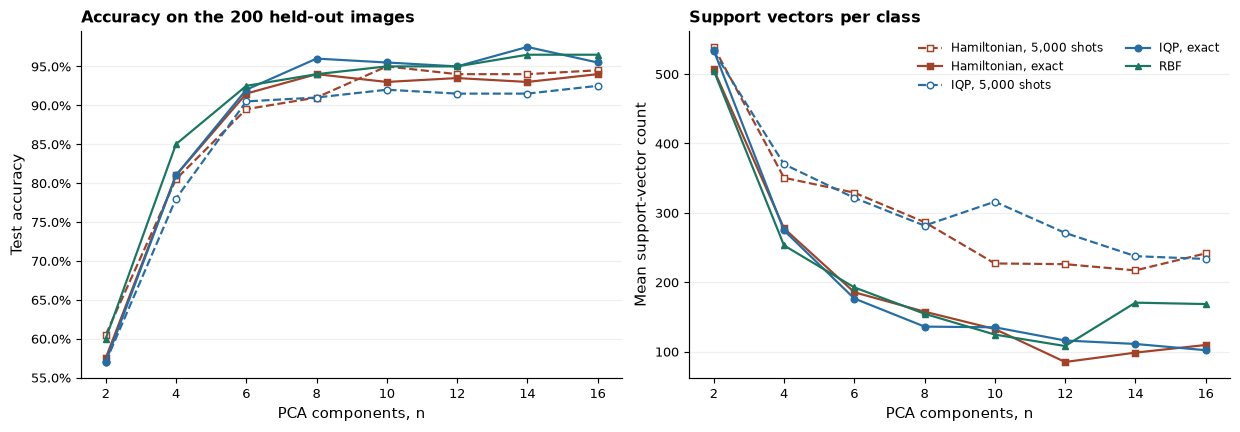

In [18]:
from matplotlib.ticker import PercentFormatter

COLORS={"IQP":"#266da4","Hamiltonian":"#a14229","RBF":"#197761"}
styles={"IQP":"o","Hamiltonian":"s","RBF":"^"}
plt.rcParams.update({"figure.dpi":105,"axes.spines.top":False,"axes.spines.right":False,
                     "legend.frameon":False,"axes.labelsize":10,"axes.titlesize":11,
                     "axes.titleweight":"semibold","font.size":9})
def metric_axes(ax,ylabel):
    ax.set_xlabel("PCA components, n")
    ax.set_xticks(DIMS)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y",alpha=.20)
def plot_condition(ax,g,value):
    for (model,shots),part in g.groupby(["model","shots"],sort=False):
        s=part.sort_values("n")
        label=model if model=="RBF" else f'{model}, '+("exact" if shots==0 else "5,000 shots")
        ax.plot(s.n,s[value],marker=styles[model],color=COLORS[model],ls="-" if shots==0 else "--",
                markerfacecolor=COLORS[model] if shots==0 else "white",markersize=4.5,label=label)

score_table=primary.pivot(index="n",columns="method",values="test_accuracy")
score_table=score_table[["IQP · exact","IQP · 5,000 shots","Hamiltonian · exact","Hamiltonian · 5,000 shots","RBF · exact"]]
show((100*score_table).rename_axis("PCs").rename_axis(None,axis=1).reset_index(),2)
fig,axes=plt.subplots(1,2,figsize=(11.7,4.0),layout="constrained")
for ax,metric,title in zip(axes,["test_accuracy","mean_sv"],["Accuracy on the 200 held-out images","Support vectors per class"]):
    plot_condition(ax,primary,metric)
    metric_axes(ax,"Test accuracy" if metric=="test_accuracy" else "Mean support-vector count")
    ax.set_title(title,loc="left")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(ncol=2,fontsize=8)
plt.show()

### The $n=16$, 5,000-shot decision

`only_quantum_correct` and `only_RBF_correct` count the discordant pairs for McNemar’s test. They can be inspected alongside the binomial and paired $p$-values. In the confusion table, “no” (1) is positive. Thus `fp` counts “yes” clips predicted as “no” and `fn` counts “no” clips predicted as “yes”. The 16-physical-qubit IQP test and the 17-physical-qubit Hamiltonian companion both use 16 input components.

In [19]:
cols=["model","qubits","scale","C","correct","total","test_accuracy","RBF_accuracy",
      "only_quantum_correct","only_RBF_correct","p_binomial","p_McNemar"]
show(formal[cols],7)
for r in formal.itertuples():
    print(f"{r.model}, {r.qubits} physical qubits: {r.correct}/{r.total} correct. "
          f"One-sided chance p = {r.p_binomial:.3g}; paired McNemar p = {r.p_McNemar:.4g}.")
    print(f"  Spread {r.variance:.5g}; single-entry shot floor {r.shot_floor:.5g}. "
          f"Bandwidth falsifier triggered: {r.reject_bandwidth}. "
          f"Concentration falsifier triggered: {r.reject_concentration}.")
counts=primary[primary.n==max(DIMS)][["method","scale","C","cv_accuracy","train_accuracy","test_accuracy","balanced_accuracy",
                                      "tn","fp","fn","tp","recall_0","recall_1","sv_0","sv_1"]]
show(counts,3)

,model,qubits,scale,C,correct,total,test_accuracy,RBF_accuracy,only_quantum_correct,only_RBF_correct,p_binomial,p_McNemar
0,Hamiltonian,17,0.01,1.0,189,200,0.945,0.965,1,5,2.5606089e-43,0.2187500
1,IQP,16,0.01,4.0,185,200,0.925,0.965,0,8,9.8971170e-39,0.0078125


Hamiltonian, 17 physical qubits: 189/200 correct. One-sided chance p = 2.56e-43; paired McNemar p = 0.2188.
  Spread 0.020415; single-entry shot floor 3.6267e-05. Bandwidth falsifier triggered: False. Concentration falsifier triggered: False.
IQP, 16 physical qubits: 185/200 correct. One-sided chance p = 9.9e-39; paired McNemar p = 0.007812.
  Spread 0.0043534; single-entry shot floor 2.1507e-05. Bandwidth falsifier triggered: True. Concentration falsifier triggered: False.


,method,scale,C,cv_accuracy,train_accuracy,test_accuracy,balanced_accuracy,tn,fp,fn,tp,recall_0,recall_1,sv_0,sv_1
0,"Hamiltonian · 5,000 shots",0.010,1.0,0.907,0.932,0.945,0.945,94,6,5,95,0.94,0.95,234,249
1,Hamiltonian · exact,0.010,128.0,0.935,0.974,0.940,0.940,93,7,5,95,0.93,0.95,105,114
2,"IQP · 5,000 shots",0.010,4.0,0.906,0.946,0.925,0.925,91,9,6,94,0.91,0.94,227,240
3,IQP · exact,0.010,512.0,0.933,0.981,0.955,0.955,92,8,1,99,0.92,0.99,102,102
4,RBF · exact,0.001,2.0,0.939,0.965,0.965,0.965,96,4,3,97,0.96,0.97,166,171


## 7. Kernel concentration and the shot-noise floor

The first two panels show exact training-pair variance across physical widths at each fixed bandwidth. The third shows the fitted log-linear trend at $\lambda=1$. At the 5,000-shot winner, the last column of the table gives $\lceil\langle p(1-p)\rangle/\operatorname{Var}(p)\rceil$, the shot count where the expected single-entry sampling variance first falls to the true pair spread.

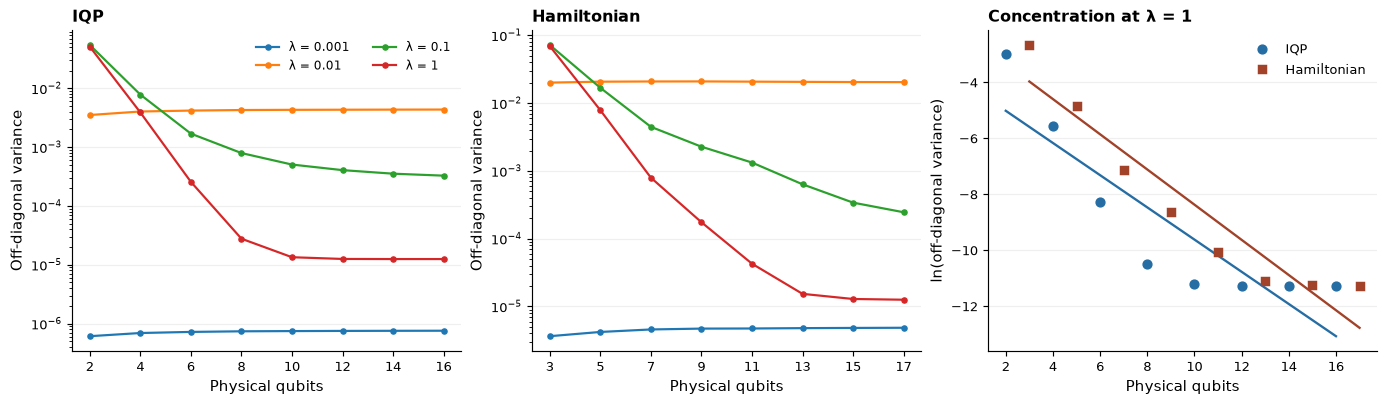

,model,slope,lower95,upper95,negative_ci,replicates
0,IQP,-0.57531,-0.77715,-0.49365,True,1000
1,Hamiltonian,-0.62869,-0.80095,-0.54951,True,1000


,model,qubits,scale,variance,shot_floor,spread_below_noise,noise_floor / spread,shots for noise ≤ spread
0,Hamiltonian,17,0.01,0.02041471,0.00003627,False,0.00177651,9
1,IQP,16,0.01,0.00435336,0.00002151,False,0.00494035,25


,model,qubits,scale,off_mean,off_median,off_sd,off_var,frob_from_I
0,IQP,16,0.001,0.9985716,0.9987456,0.0008701,0.0000008,1197.7870070
1,IQP,16,0.010,0.8716327,0.8806607,0.0659800,0.0043534,1048.5145355
2,IQP,16,0.100,0.0182276,0.0131996,0.0180956,0.0003275,30.8086556
3,IQP,16,1.000,0.0000304,0.0000123,0.0035370,0.0000125,4.2427506
4,Hamiltonian,17,0.001,0.9965166,0.9969686,0.0022030,0.0000049,1195.3245144
5,Hamiltonian,17,0.010,0.7196608,0.7388059,0.1428801,0.0204147,880.0818101
6,Hamiltonian,17,0.100,0.0049970,0.0009689,0.0156728,0.0002456,19.7319341
7,Hamiltonian,17,1.000,0.0001155,0.0000311,0.0035470,0.0000126,4.2569034


In [20]:
fig,axes=plt.subplots(1,3,figsize=(13.1,3.75),layout="constrained")
for col,model in enumerate(("IQP","Hamiltonian")):
    g=concentration[concentration.model==model]
    ax=axes[col]
    for scale,part in g.groupby("scale"):
        ax.semilogy(part.qubits,part.off_var,"o-",ms=3.5,label=f"λ = {scale:g}")
    ax.set_xticks(g.qubits.unique())
    ax.set_xlabel("Physical qubits")
    ax.set_ylabel("Off-diagonal variance")
    ax.set_title(model,loc="left")
    ax.grid(axis="y",alpha=.2)
    if col==0:
        ax.legend(fontsize=8,ncol=2)
ax=axes[2]
for r in slopes.itertuples():
    p=concentration[(concentration.model==r.model)&(concentration.scale==1)]
    ax.plot(p.qubits,np.log(p.off_var),styles[r.model],color=COLORS[r.model],label=r.model)
    ax.plot(p.qubits,r.intercept+r.slope*p.qubits,color=COLORS[r.model],lw=1.6)
ax.set(xlabel="Physical qubits",ylabel="ln(off-diagonal variance)")
ax.set_title("Concentration at λ = 1",loc="left")
ax.legend()
ax.grid(axis="y",alpha=.2)
plt.show()
show(slopes[["model","slope","lower95","upper95","negative_ci","replicates"]],5)
floors=formal[["model","qubits","scale","variance","shot_floor","spread_below_noise"]].copy()
floors["noise_floor / spread"]=floors.shot_floor/floors.variance
floors["shots for noise ≤ spread"]=np.ceil(PRIMARY_SHOTS*floors.shot_floor/floors.variance).astype(int)
show(floors,8)

at16=concentration[concentration.n==16]
show(at16[["model","qubits","scale","off_mean","off_median","off_sd","off_var","frob_from_I"]],7)

## 8. Bandwidth, accuracy and support vectors

At each scale the heatmap shows the highest five-fold accuracy over $C$. The lower panels show the descriptive 16-component hold-out sweep with $C$ chosen independently by training CV at each scale. The model winners in Section 6 were locked using training folds. The distance from identity and support-vector panels retain the paper’s two measures of kernel geometry and classifier structure. A separate 100-point classical curve holds the selected $C$ fixed. Its held-out scores are descriptive and are excluded from tuning.

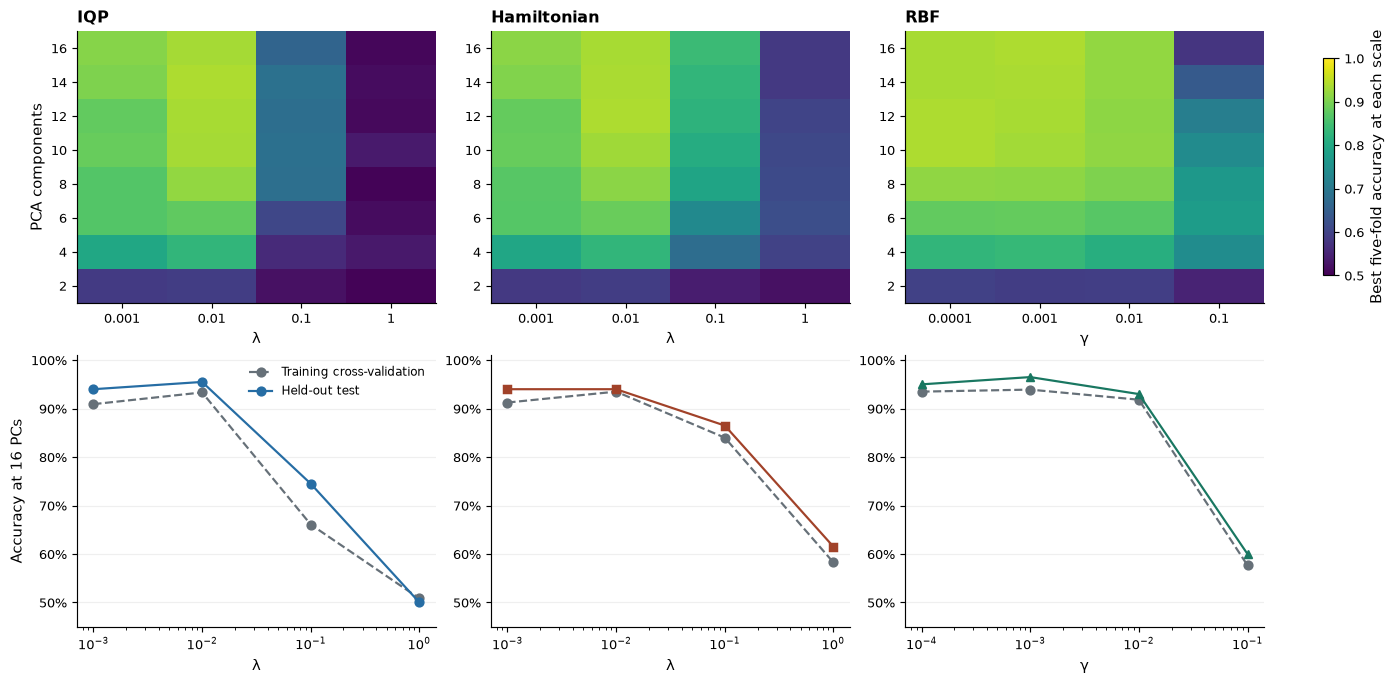

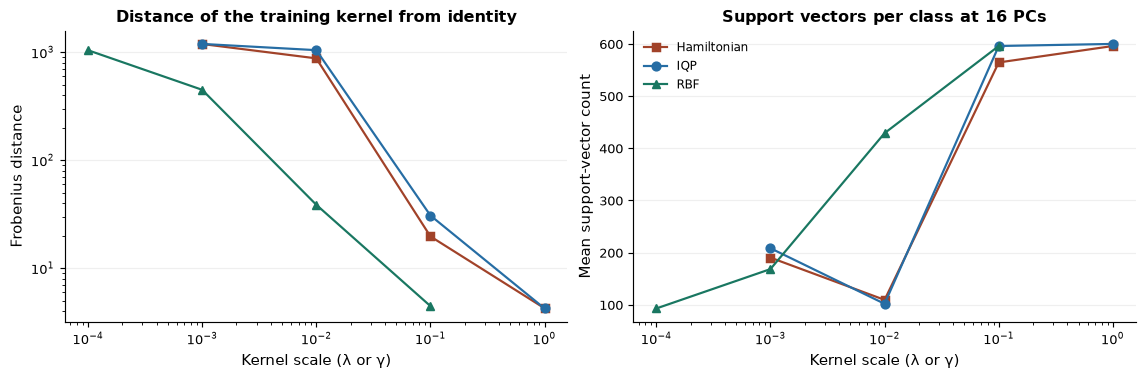

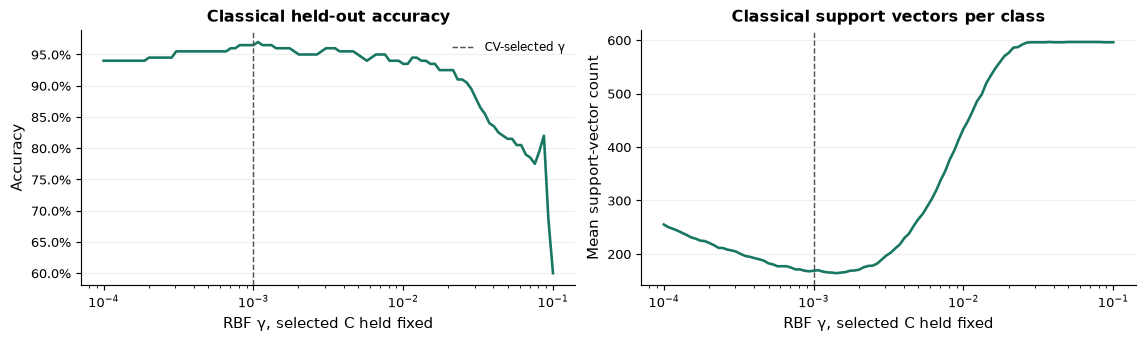

In [21]:
fig,axes=plt.subplots(2,3,figsize=(13.2,6.4),layout="constrained")
for j,model in enumerate(MODELS):
    g=grid[(grid.model==model)&(grid.condition=="exact")].groupby(["n","scale"]).cv_accuracy.max().unstack()
    image=axes[0,j].imshow(g.to_numpy(),origin="lower",aspect="auto",cmap="viridis",vmin=.5,vmax=1.)
    axes[0,j].set_yticks(range(len(g.index)),g.index)
    axes[0,j].set_xticks(range(len(g.columns)),[f"{a:g}" for a in g.columns])
    axes[0,j].set_title(model,loc="left")
    axes[0,j].set_xlabel("γ" if model=="RBF" else "λ")
    if j==0:
        axes[0,j].set_ylabel("PCA components")
    d=by_bandwidth[by_bandwidth.model==model].sort_values("scale")
    axes[1,j].semilogx(d.scale,d.cv_accuracy,"o--",color="#667078",label="Training cross-validation")
    axes[1,j].semilogx(d.scale,d.test_accuracy,styles[model]+"-",color=COLORS[model],label="Held-out test")
    axes[1,j].set(xlabel="γ" if model=="RBF" else "λ",ylim=(.45,1.01))
    axes[1,j].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1,j].grid(axis="y",alpha=.2)
axes[1,0].set_ylabel("Accuracy at 16 PCs")
axes[1,0].legend(fontsize=8)
fig.colorbar(image,ax=axes[0,:],label="Best five-fold accuracy at each scale",shrink=.8)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(10.8,3.5),layout="constrained")
for m,g in by_bandwidth.groupby("model"):
    g=g.sort_values("scale")
    for ax,col in zip(axes,("frob_from_I","mean_sv")):
        ax.plot(g.scale,g[col],styles[m]+"-",color=COLORS[m],label=m)
        ax.set_xscale("log")
        ax.set_xlabel("Kernel scale (λ or γ)")
        ax.grid(axis="y",alpha=.2)
axes[0].set(ylabel="Frobenius distance",title="Distance of the training kernel from identity")
axes[0].set_yscale("log")
axes[1].set(ylabel="Mean support-vector count",title="Support vectors per class at 16 PCs")
axes[1].legend(fontsize=8)
plt.show()

dense=supplementary[supplementary.experiment=="RBF curve"].sort_values("scale")
assert len(dense)==100
fig,axes=plt.subplots(1,2,figsize=(10.8,3.15),layout="constrained")
for ax,values,title in zip(axes,["test_accuracy","mean_sv"],["Classical held-out accuracy","Classical support vectors per class"]):
    ax.semilogx(dense.scale,dense[values],color=COLORS["RBF"],lw=1.8)
    choice=best[(best.n==16)&(best.model=="RBF")].iloc[0]
    ax.axvline(choice.scale,color="#555",ls="--",lw=1,label="CV-selected γ")
    ax.set(xlabel="RBF γ, selected C held fixed",title=title)
    ax.grid(axis="y",alpha=.2)
axes[0].set_ylabel("Accuracy")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_ylabel("Mean support-vector count")
axes[0].legend(fontsize=8)
plt.show()

## 9. Shot count and PSD correction

These curves use the 5,000-shot winner at each point. A value above one in the middle panel means that the mean sampling variance exceeds the underlying spread of the ideal entries. `observed_var` is the raw off-diagonal spread after sampling. `estimated_shot_floor` uses the counts alone, averaging $\hat p(1-\hat p)/(S-1)$. The relative PSD correction is $\|K_+-K_{\rm raw}\|_F/\|K_{\rm raw}\|_F$.

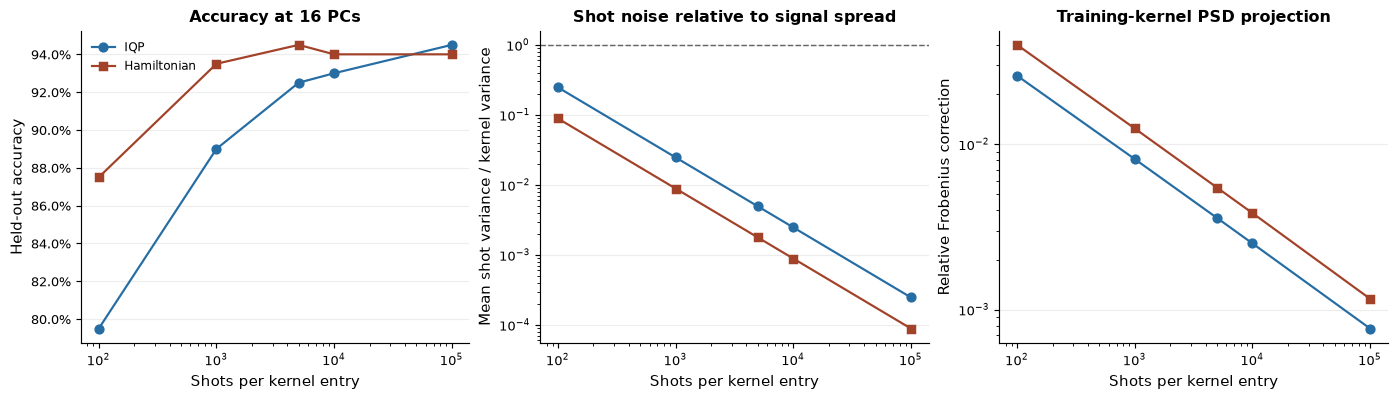

,model,qubits,shots,scale,C,test_accuracy,off_var,observed_var,exact_shot_floor,estimated_shot_floor,psd_relative_change
0,Hamiltonian,17,100,0.01,1.0,0.875,0.0204147,0.0222439,0.0018133,0.0018129,0.0399089
1,Hamiltonian,17,1000,0.01,1.0,0.935,0.0204147,0.0206005,0.0001813,0.0001813,0.0124558
2,Hamiltonian,17,5000,0.01,1.0,0.945,0.0204147,0.0204494,0.0000363,0.0000363,0.0054676
3,Hamiltonian,17,10000,0.01,1.0,0.940,0.0204147,0.0204334,0.0000181,0.0000181,0.0038345
4,Hamiltonian,17,100000,0.01,1.0,0.940,0.0204147,0.0204166,0.0000018,0.0000018,0.0011617
5,IQP,16,100,0.01,4.0,0.795,0.0043534,0.0054255,0.0010754,0.0010756,0.0259704
6,IQP,16,1000,0.01,4.0,0.890,0.0043534,0.0044649,0.0001075,0.0001075,0.0081316
7,IQP,16,5000,0.01,4.0,0.925,0.0043534,0.0043752,0.0000215,0.0000215,0.0035825
8,IQP,16,10000,0.01,4.0,0.930,0.0043534,0.0043649,0.0000108,0.0000108,0.0025132
9,IQP,16,100000,0.01,4.0,0.945,0.0043534,0.0043544,0.0000011,0.0000011,0.0007680


In [22]:
fig,axes=plt.subplots(1,3,figsize=(13.2,3.7),layout="constrained")
for model in ("IQP","Hamiltonian"):
    g=fits[(fits.model==model)&(fits.n==max(DIMS))&(fits.shots>0)].sort_values("shots")
    assert g[["scale","C"]].drop_duplicates().shape[0]==1
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xlabel("Shots per kernel entry")
        ax.grid(axis="y",alpha=.22)
    axes[0].plot(g.shots,g.test_accuracy,styles[model]+"-",color=COLORS[model],label=model)
    axes[1].loglog(g.shots,g.exact_shot_floor/g.off_var,styles[model]+"-",color=COLORS[model])
    axes[2].loglog(g.shots,g.psd_relative_change,styles[model]+"-",color=COLORS[model])
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(ylabel="Held-out accuracy",title="Accuracy at 16 PCs")
axes[0].legend(fontsize=8)
axes[1].axhline(1,color="#666",ls="--",lw=1)
axes[1].set(ylabel="Mean shot variance / kernel variance",title="Shot noise relative to signal spread")
axes[2].set(ylabel="Relative Frobenius correction",title="Training-kernel PSD projection")
plt.show()
shot_columns=["model","qubits","shots","scale","C","test_accuracy","off_var","observed_var",
             "exact_shot_floor","estimated_shot_floor","psd_relative_change"]
show(fits[(fits.n==16)&(fits.shots>0)][shot_columns].sort_values(["model","shots"]),7)

## 10. Trotter steps, gate precision and initialization

The Trotter comparison uses all eight PCA dimensions with $(\lambda,C)$ fixed to the exact $T=40$ winner at each dimension. At 16 components, the next experiment rounds each feature-dependent rotation angle in radians to one through six decimal places. The Haar preparation is fixed. The initialization experiment uses 20 seeds at four components and compares the validation-selected bandwidth with $\lambda=1$. A second table repeats the 20-seed comparison at the paper’s $T=20$, using training-fold-selected $C$ for each fixed bandwidth at that Trotter depth.

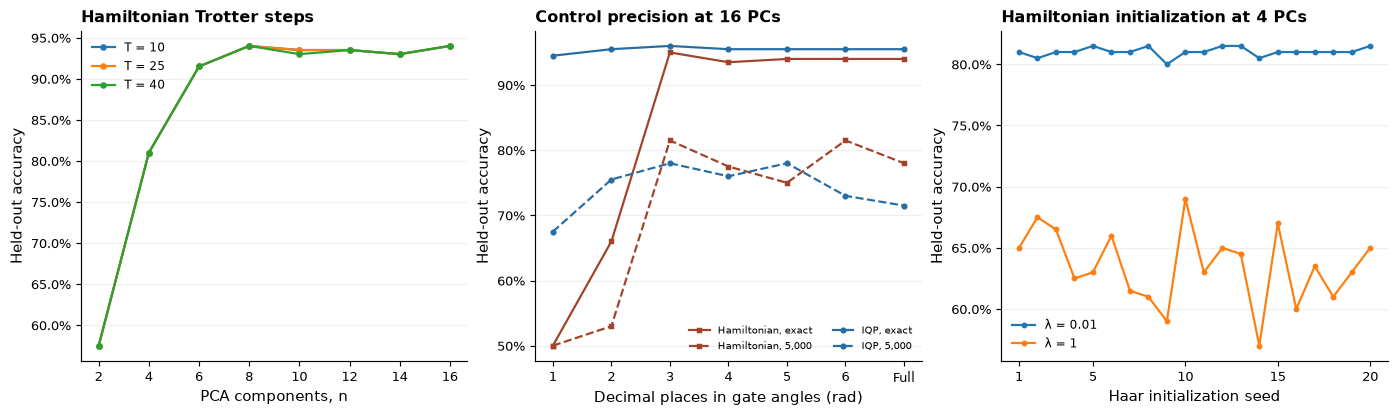

Largest accuracy difference across the three Trotter depths at a fixed dimension: 0.5 percentage points.


,n,T,scale,C,test_accuracy,off_var
0,16,10,0.01,128.0,0.94,0.0204431
1,16,25,0.01,128.0,0.94,0.0204206
2,16,40,0.01,128.0,0.94,0.0204147


,scale,count,mean,std,min,max
0,0.01,20,0.8103,0.0038,0.80,0.815
1,1.00,20,0.6350,0.0303,0.57,0.690


,T,scale,C,count,mean,std,min,max
0,20,0.01,64.0,20,0.8103,0.0038,0.800,0.815
1,20,1.00,512.0,20,0.5727,0.0304,0.515,0.620


In [23]:
fig,axes=plt.subplots(1,3,figsize=(13.2,3.85),layout="constrained")
trot=controls[controls.experiment=="Trotter steps"]
for t,g in trot.groupby("value"):
    axes[0].plot(g.n,g.test_accuracy,"o-",ms=3.5,label=f"T = {int(t)}")
metric_axes(axes[0],"Held-out accuracy")
axes[0].set_title("Hamiltonian Trotter steps",loc="left")
axes[0].legend(fontsize=8)
angles=controls[controls.experiment=="Gate angle decimals"].copy()
angles["position"]=angles.value.map(lambda x:7 if x<0 else x)
for model,g in angles.groupby("model"):
    g=g.sort_values("position")
    for metric,line in [("test_accuracy","-"),("shot_accuracy","--")]:
        axes[1].plot(g.position,g[metric],ls=line,marker=styles[model],ms=3.2,color=COLORS[model],
                     label=model+(", exact" if line=="-" else ", 5,000"))
axes[1].set_xticks(range(1,8),["1","2","3","4","5","6","Full"])
axes[1].set(xlabel="Decimal places in gate angles (rad)",ylabel="Held-out accuracy")
axes[1].set_title("Control precision at 16 PCs",loc="left")
axes[1].legend(fontsize=7,ncol=2)
seeds=controls[controls.experiment=="Haar seed"]
for scale,g in seeds.groupby("scale"):
    axes[2].plot(g.value,g.test_accuracy,"o-",ms=3,label=f"λ = {scale:g}")
axes[2].set_xticks([1,5,10,15,20])
axes[2].set(xlabel="Haar initialization seed",ylabel="Held-out accuracy")
axes[2].set_title("Hamiltonian initialization at 4 PCs",loc="left")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y",alpha=.2)
plt.show()
trot_scores=trot.pivot(index="n",columns="value",values="test_accuracy")
print(f"Largest accuracy difference across the three Trotter depths at a fixed dimension: "
      f"{100*(trot_scores.max(axis=1)-trot_scores.min(axis=1)).max():.1f} percentage points.")
show(trot[trot.n==16][["n","value","scale","C","test_accuracy","off_var"]].rename(columns={"value":"T"}),7)
show(seeds.groupby("scale").test_accuracy.agg(["count","mean","std","min","max"]).reset_index(),4)

paper_seeds=supplementary[supplementary.experiment=="20-step initialization"]
show(paper_seeds.groupby(["T","scale","C"]).test_accuracy.agg(["count","mean","std","min","max"]).reset_index(),4)

### One Speech Commands pair

The left panel varies bandwidth on the first training/test clip pair. Dashed guides show the paper’s heuristic $K(1)^\lambda$, where $K(1)$ is the measured exact fidelity of this same pair. The right panel varies physical width at $\lambda=1$ for the second training/test pair. Each clip follows the project’s training-fitted preprocessing. The concentration tests above use the full training-pair distribution.

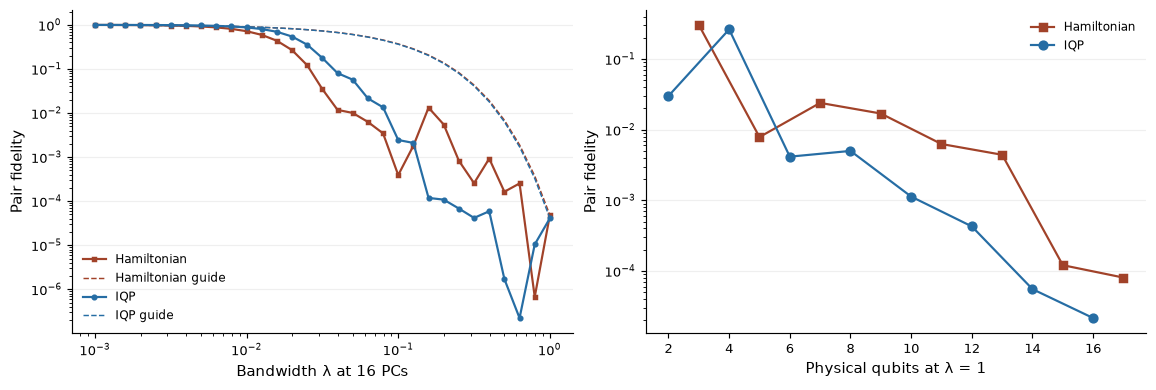

First training example: official row 1694, label 1. First test example: official row 419, label 0.
Second pair, official train/test row IDs: 5133 and 769.


In [24]:
fig,axes=plt.subplots(1,2,figsize=(10.9,3.6),layout="constrained")
for model,g in one_pair.groupby("model"):
    at_n=g[g.n==max(DIMS)].sort_values("scale")
    at_one=g[np.isclose(g.scale,1.)].sort_values("qubits")
    axes[0].semilogx(at_n.scale,np.maximum(at_n.fidelity,1e-20),styles[model]+"-",ms=3.2,color=COLORS[model],label=model)
    base=at_n.loc[np.isclose(at_n.scale,1.),"fidelity"].item()
    axes[0].plot(at_n.scale,np.maximum(base**at_n.scale,1e-20),ls="--",lw=1,color=COLORS[model],label=model+" guide")
    second=[fidelity_matrix(final_view[[1,len(y)+1],:int(r.n)],model,1.)[0,1] for r in at_one.itertuples()]
    axes[1].semilogy(at_one.qubits,np.maximum(second,1e-20),styles[model]+"-",color=COLORS[model],label=model)
axes[0].set_yscale("log")
axes[0].set(xlabel="Bandwidth λ at 16 PCs",ylabel="Pair fidelity")
axes[1].set(xlabel="Physical qubits at λ = 1",ylabel="Pair fidelity")
for ax in axes:
    ax.grid(axis="y",alpha=.2)
    ax.legend(fontsize=8)
plt.show()
print(f'First training example: official row {train_ids[0]}, label {y[0]}. '
      f'First test example: official row {test_ids[0]}, label {y_test[0]}.')

print(f"Second pair, official train/test row IDs: {train_ids[1]} and {test_ids[1]}.")

## 11. Calibrated noise and physical-device comparison

The first table summarizes 28 distinct off-diagonal pairs and eight self-overlaps at each physical qubit count. Mean absolute error compares Aer’s all-zero frequencies with the exact result. The second table gives the full two-qubit IQP classifier results on the 200 held-out test clips. Both use the archived IBM calibration identified below.

IBM Manila calibration: 2024-05-27 15:27:23-03:00. 108 distinct overlap circuits × 5,000 shots.
Timing estimate on the archived target: 517 s. Selection and timing are recalculated for the selected live backend.


,model,n,qubits,off_diagonal_pairs,mean_two_qubit_gates,exact_variance,exact_diagonal,aer_variance,aer_diagonal,aer_MAE_vs_exact
0,IQP,2,2,28,8.0,0.002731,1.0,0.002004,0.894950,0.098147
1,Hamiltonian,2,3,28,960.0,0.007256,1.0,0.000016,0.145875,0.738788
2,IQP,4,4,28,88.0,0.003117,1.0,0.000466,0.436125,0.499795


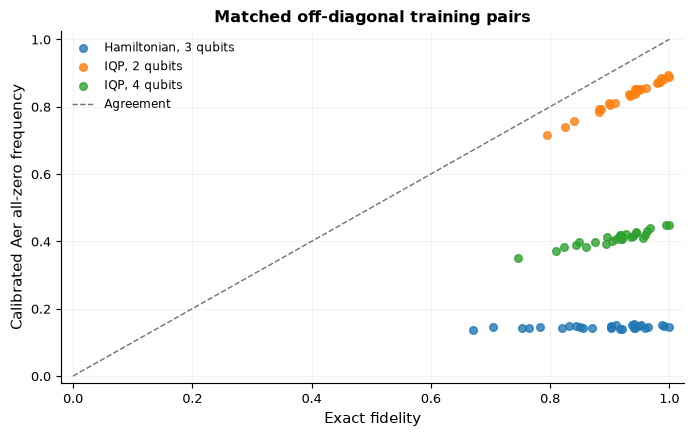

,control,qubits,training,test,shots,scale,C,test_accuracy,balanced_accuracy,tn,fp,fn,tp,off_var,diagonal,psd_relative_change,direct_Aer_error
0,Calibrated gate errors,2,1200,200,5000,0.01,1.0,0.575,0.575,68,32,53,47,0.002930,0.943209,0.003647,3.330669e-16
1,Calibrated gates and readout,2,1200,200,5000,0.01,1.0,0.585,0.585,69,31,52,48,0.002457,0.891097,0.004427,6.661338e-16


In [25]:
print(f"IBM Manila calibration: {device_meta['calibration_date']}. "
      f"{device_meta['circuits']} distinct overlap circuits × {device_meta['shots']:,} shots.")
print(f"Timing estimate on the archived target: {device_meta['estimated_s']:.0f} s. "
      "Selection and timing are recalculated for the selected live backend.")
show(summarize_device(device_pairs),6)
fig,ax=plt.subplots(figsize=(6.5,4.05),layout="constrained")
for (model,q),g in device_pairs[device_pairs.i!=device_pairs.j].groupby(["model","qubits"]):
    ax.scatter(g.exact,g.aer,s=27,alpha=.78,label=f"{model}, {q} qubits")
ax.plot([0,1],[0,1],ls="--",lw=1,color="#707778",label="Agreement")
ax.set(xlabel="Exact fidelity",ylabel="Calibrated Aer all-zero frequency",
       xlim=(-.02,1.025),ylim=(-.02,1.025),title="Matched off-diagonal training pairs")
ax.grid(alpha=.15)
ax.legend(fontsize=8,loc="best")
plt.show()
show(calibrated_model[["control","qubits","training","test","shots","scale","C","test_accuracy","balanced_accuracy",
                       "tn","fp","fn","tp","off_var","diagonal","psd_relative_change","direct_Aer_error"]],6)

### Physical IBM Quantum execution

Set `IBM_BACKEND` to an accessible backend and `QPU_SECONDS_LEFT` to the remaining monthly allowance. Use `IBM_MODE="plan"` to compile and estimate, `"submit"` to dispatch one job and `"collect"` to retrieve the counts. A saved IBM Runtime account is required for those modes. Keep the experiment’s cache folder to retain its job receipt, ISA circuits and matched Aer results.

The planner estimates compiled circuit duration, reset and repetition delays, adds an overhead allowance and caps the proposed run at 600 seconds. If necessary it reduces the balanced subset from four images per class to three or two. Budget estimates are backend-dependent. Collection reports actual usage and a comparison on the identical pairs and physical layouts.

In [26]:
IBM_MODE="off"            # "plan", "submit", or "collect"
IBM_BACKEND=""             # A currently accessible IBM Quantum backend name
QPU_SECONDS_LEFT=600       # Actual remaining seconds this month, at most 600
RECOVERY_JOB_ID=None       # Existing IBM job ID, for interrupted receipt writes
if IBM_MODE=="off":
    print("Physical IBM QPU measurement pending. The saved noise-model tables come from Qiskit Aer.")
else:
    live=device_run(IBM_MODE,IBM_BACKEND,best,QPU_SECONDS_LEFT,RECOVERY_JOB_ID)
    if "subset_results" in live:
        print(f"IBM job {live['job_id']}. Reported quantum usage: {live['actual_usage']}")
        show(summarize_device(live["subset_results"]),6)
        display(live["subset_results"])
    else:
        print(json.dumps(live,indent=2))

Physical IBM QPU measurement pending. The saved noise-model tables come from Qiskit Aer.


## 12. Interpretation

The bandwidth and concentration criteria are evaluated independently for each feature map. A paired test that does not detect a difference from RBF does not establish equal performance. These conclusions apply to this fixed Speech Commands split, search grid and simulator protocol.

In [27]:
for r in formal.itertuples():
    a=slopes.loc[slopes.model==r.model].iloc[0]
    print(f"{r.model}, {r.qubits} physical qubits, λ = {r.scale:g}, C = {r.C:g}.")
    print(f"  At 5,000 shots it classified {r.correct} of {r.total} held-out clips correctly "
          f"({r.test_accuracy:.1%}). Tuned RBF at 16 PCs scored {r.RBF_accuracy:.1%}.")
    triggered=[]
    if r.spread_below_noise:
        triggered.append("spread below shot noise")
    if r.chance_test_failed:
        triggered.append("one-sided chance test")
    if r.significantly_below_RBF:
        triggered.append("paired shortfall versus RBF")
    print("  Bandwidth criterion: "+("rejected ("+", ".join(triggered)+")." if triggered else
          "none of the three rejection conditions was met."))
    print(f"  At λ = 1, log-variance slope {a.slope:.3f} per physical qubit "
          f"(95% bootstrap interval {a.lower95:.3f} to {a.upper95:.3f}).")
rng=rng_for("chance-control",SEED)
uniform=rng.choice(list(LABELS),size=len(y_test))
print(f"Balanced random guessing has expected accuracy 50%. One seeded draw scored "
      f"{accuracy_score(y_test,uniform):.1%} on these {len(y_test)} labels.")

Hamiltonian, 17 physical qubits, λ = 0.01, C = 1.
  At 5,000 shots it classified 189 of 200 held-out clips correctly (94.5%). Tuned RBF at 16 PCs scored 96.5%.
  Bandwidth criterion: none of the three rejection conditions was met.
  At λ = 1, log-variance slope -0.629 per physical qubit (95% bootstrap interval -0.801 to -0.550).
IQP, 16 physical qubits, λ = 0.01, C = 4.
  At 5,000 shots it classified 185 of 200 held-out clips correctly (92.5%). Tuned RBF at 16 PCs scored 96.5%.
  Bandwidth criterion: rejected (paired shortfall versus RBF).
  At λ = 1, log-variance slope -0.575 per physical qubit (95% bootstrap interval -0.777 to -0.494).
Balanced random guessing has expected accuracy 50%. One seeded draw scored 53.0% on these 200 labels.


### Sources

- Muhammad Ahmad Masood and Muhammad Waqas, *Kernel Concentration and Bandwidth Scaling in Quantum Machine Learning*, course project proposal, Sections II–V and Table I.
- Shaydulin and Wild, *Importance of Kernel Bandwidth in Quantum Machine Learning*, Physical Review A **106**, 042407 (2022). [Paper](https://arxiv.org/abs/2111.05451v4) · [Authors’ code and data at the pinned revision](https://github.com/rsln-s/Importance-of-Kernel-Bandwidth-in-Quantum-Machine-Learning/tree/3c0717742c505c66cca4559a0c8b3da1b95ca4fc)
- Warden, *Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition*, arXiv:1804.03209 (2018), version 0.02 archive and official partition lists. [Paper](https://arxiv.org/abs/1804.03209) · [Archive](http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz)
- IBM Quantum, backend calibration snapshots, sampling interface and execution timing. [Fake provider](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider) · [SamplerV2](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/sampler-v2) · [Job time estimates](https://quantum.cloud.ibm.com/docs/en/guides/estimate-job-run-time)